# 3.3.0-Clustering Level 2

**Inés Sentís**

Date of execution

In [1]:
Sys.Date()

[1] "2025-11-27"

## Libraries

In [2]:
options(warn = -1, verbose = FALSE)
suppressMessages(suppressWarnings({
library(Signac)
library(Seurat)
library(tidyverse)
library(ggplot2)
library(gridExtra)
library(scran)
library(scater)
}))

## Parameters

In [3]:
patient <- "p10"
subproj <- "AVGUSTINOVA_02_03"

assay_ch <- "RNA_decontx"

In [4]:
source(here::here(glue::glue("{subproj}/multiome_analysis/misc/paths.R")))
source(here::here(glue::glue("{subproj}/multiome_analysis/utils/style.R")))
source(here::here(glue::glue("{subproj}/multiome_analysis/utils/variables.R")))
source(here::here(glue::glue("utils/bin.R")))

"{clust}/{plt_dir}/level_2" %>%
  glue::glue() %>%
  here::here() %>%
  dir.create(path = .,
           showWarnings = FALSE,
           recursive = TRUE)

"{clust}/{robj_dir}/level_2" %>%
  glue::glue() %>%
  here::here() %>%
  dir.create(path = .,
           showWarnings = FALSE,
           recursive = TRUE)

set.seed(0)

In [5]:
var_name <- paste0("colors_", patient)
colors_list <- get(var_name)

In [6]:
var_name <- paste0("comp_", patient)
dcomp <- get(var_name)
dcomp

$rna
 [1]  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25
[26] 26 27 28 29 30

$atac
 [1]  2  3  4  5  6  7  8  9 10 11 12 13 14 15

In [7]:
var_name <- paste0("topc_", patient)
top_counts <- get(var_name)
top_counts

[1] "MALAT1"

In [8]:
var_name <- paste0("reso_l1_", patient)
reso <- get(var_name)
reso

[1] 0.25

## Load data

In [9]:
seurat_obj <- readRDS(here::here(glue::glue("{clust}/{robj_dir}/level_1/3.2.0-l1_anno_{patient}.rds")))
DefaultAssay(seurat_obj) <- assay_ch

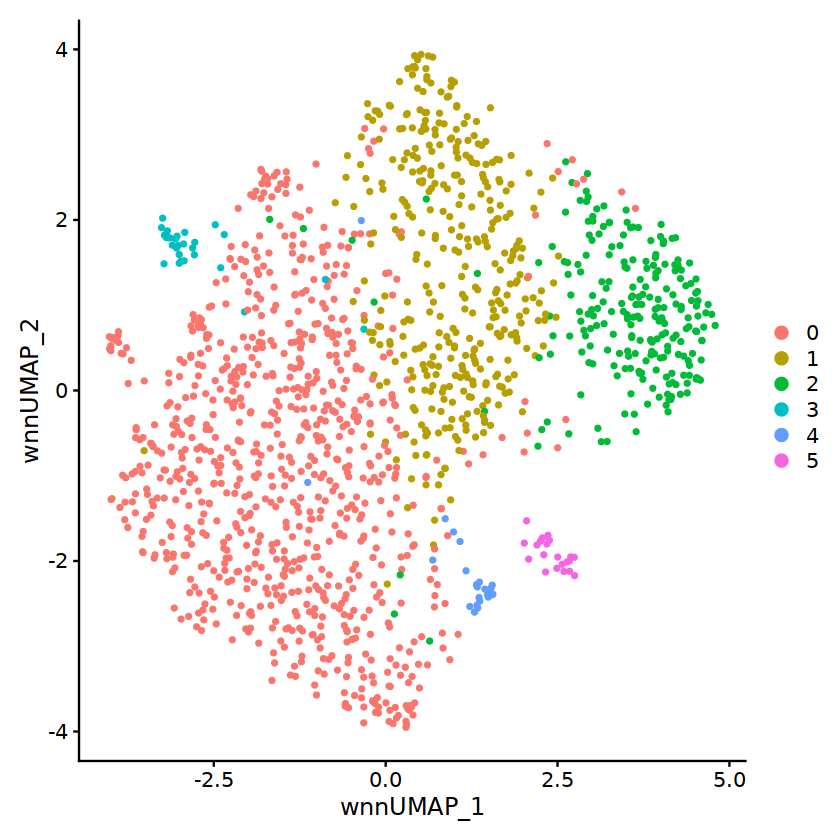

In [10]:
DimPlot(seurat_obj, reduction = "wnn.umap") 

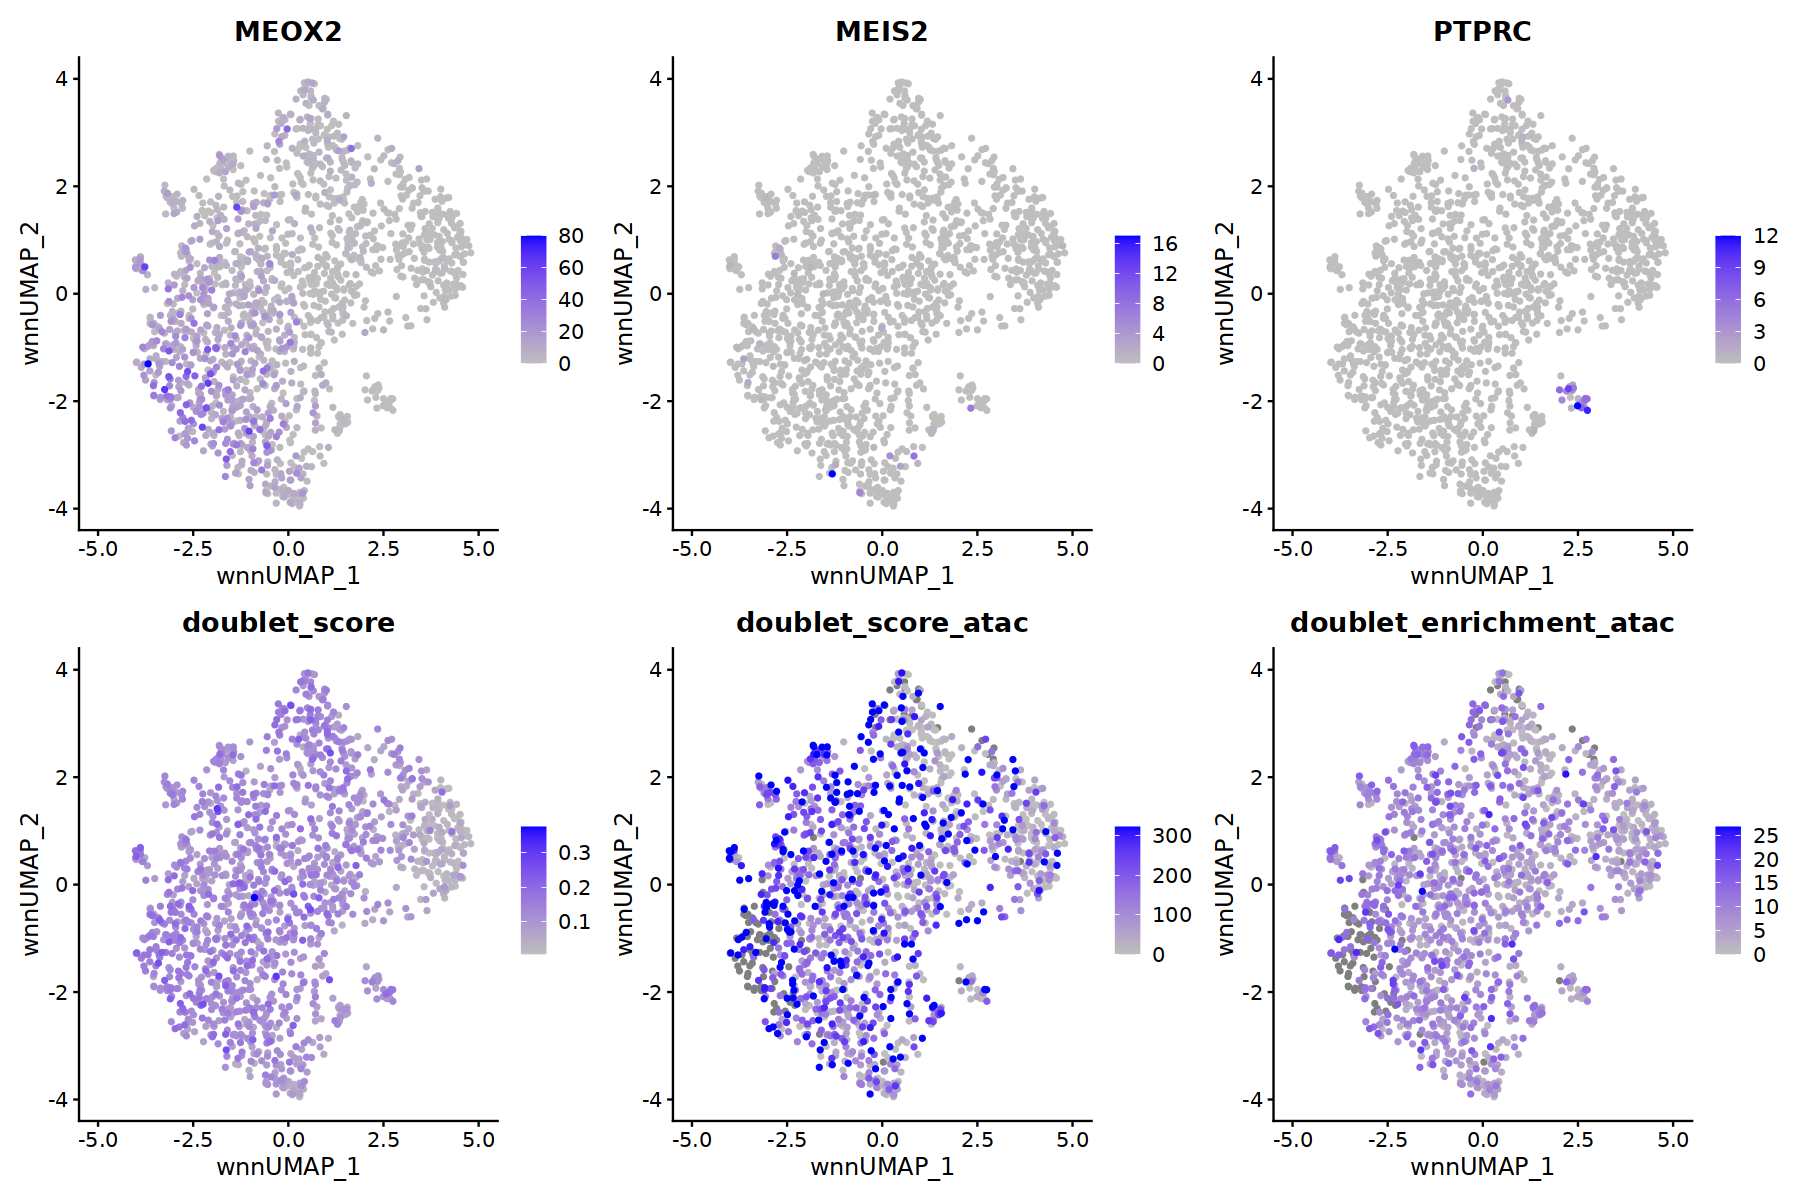

In [11]:
options(repr.plot.width = 15, repr.plot.height = 10)
FeaturePlot(seurat_obj, reduction = "wnn.umap", 
            feature=c("MEOX2","MEIS2","PTPRC",
                      "doublet_score","doublet_score_atac","doublet_enrichment_atac"), 
            ncol=3,cols = c("gray", "blue"),  order=T)

## Re-normalize

In [12]:
DefaultAssay(seurat_obj) <- assay_ch

In [13]:
keep_genes <- data.frame(rowSums(as.matrix(seurat_obj[[assay_ch]]@counts)) != 0)
colnames(keep_genes) <- "logical"
keep_genes <- subset(keep_genes, logical==TRUE)
seurat_obj[[assay_ch]]@counts <- seurat_obj[[assay_ch]]@counts[rownames(keep_genes), ]
seurat_obj[[assay_ch]]@data <- seurat_obj[[assay_ch]]@data[rownames(keep_genes), ]

In [14]:
seurat_obj <- NormalizeData(
  seurat_obj,
  normalization.method = "LogNormalize",
  scale.factor = 1e4
)

In [15]:
# compute the variance and mean of the log-expression values 
sce <- as.SingleCellExperiment(seurat_obj, assay=assay_ch)
gene_var <- modelGeneVar(sce)

tops <- gene_var %>% 
    as.data.frame() %>% 
    arrange(desc(total)) %>% 
    head(n=20)

plt <- gene_var %>% 
  as.data.frame() %>% 
  ggplot(aes(mean, total)) +
  geom_point() +
  geom_line(aes(y = tech), colour = "dodgerblue", size = 1) +
  labs(x = "Mean of log-expression", y = "Variance of log-expression")+
  geom_text(data=tops, aes(mean,total,label=rownames(tops)))

hvgs <- getTopHVGs(gene_var,fdr.threshold = 0.05)

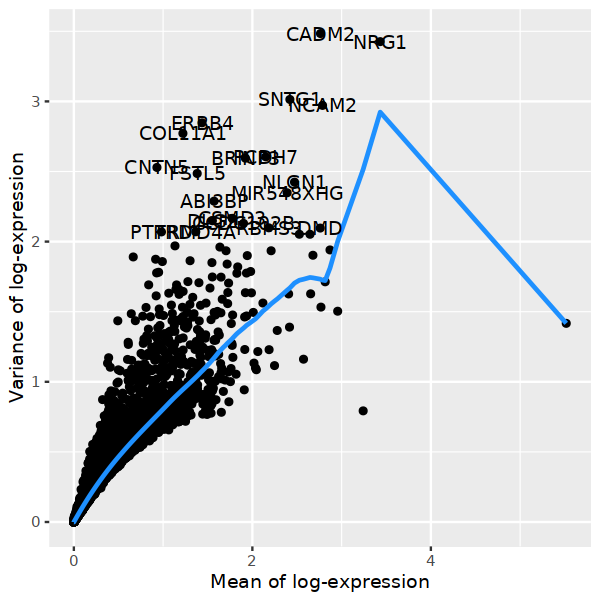

In [16]:
options(repr.plot.width = 5, repr.plot.height = 5)
plt

In [17]:
print(length(hvgs))
hvgs <- setdiff(hvgs, top_counts)
print(length(hvgs))

[1] 2300
[1] 2300


In [18]:
VariableFeatures(seurat_obj) <- hvgs

seurat_obj <- seurat_obj %>%
  ScaleData() %>% 
  RunPCA() 

Centering and scaling data matrix

PC_ 1 
Positive:  CADM2, PCDH7, BRINP3, CSMD3, DOK6, SNTG1, ABI3BP, NCAM2, DLG2, FRMD4A 
	   GPC6, KCNMB2, CALCRL, TCF4, FSTL5, GAS2, AC121154.1, ERBB4, TMEFF2, ALCAM 
	   CCDC178, PTPRD, AC013287.1, KCNMB2-AS1, LINC02511, ADGRL3, PKHD1, PALLD, GPC3, FN1 
Negative:  RPL36, RPS29, RPL35A, RPS12, S100A6, RPS28, FTL, RPL35, RPL26, RPS27 
	   RPL39, RPS21, RPL9, RPL38, TMSB4X, RPL18A, RPL27, RPS15A, TPT1, RPL32 
	   RPS13, PLCG2, RPS11, FAU, VIM, ANXA2, RPL29, RPS20, RPS10, RPL31 
PC_ 2 
Positive:  RPS12, S100A6, RPL29, RPL36, RPL32, HSPB1, RPS29, RPS13, RPL35, RPL31 
	   RPS20, RPL26, MT-ND3, AHNAK, RPS21, LGALS1, RPL38, RPS11, MT-ND2, RPS10 
	   RPL35A, MT-ATP8, RPS27, RPS28, CRYAB, RPL9, UBA52, MT-ND1, S100P, TM4SF1 
Negative:  PTPRC, DOCK8, DOCK2, APBB1IP, IKZF1, ATXN1, LCP2, CHST11, FYB1, SRGN 
	   CD53, SKAP1, VAV3, SLA, GNG2, GPRIN3, BIN2, MDFIC, CD247, ITGA4 
	   TOX, SAMSN1, FRMD4B, ARHGAP25, CCL5, TMC8, SNTB1, LINC00299, SLFN12L, CCL3 
PC_ 3 
Po

In [19]:
markers = c("GPC6","ERBB4", "GPC3","MEOX2","PTPRC")

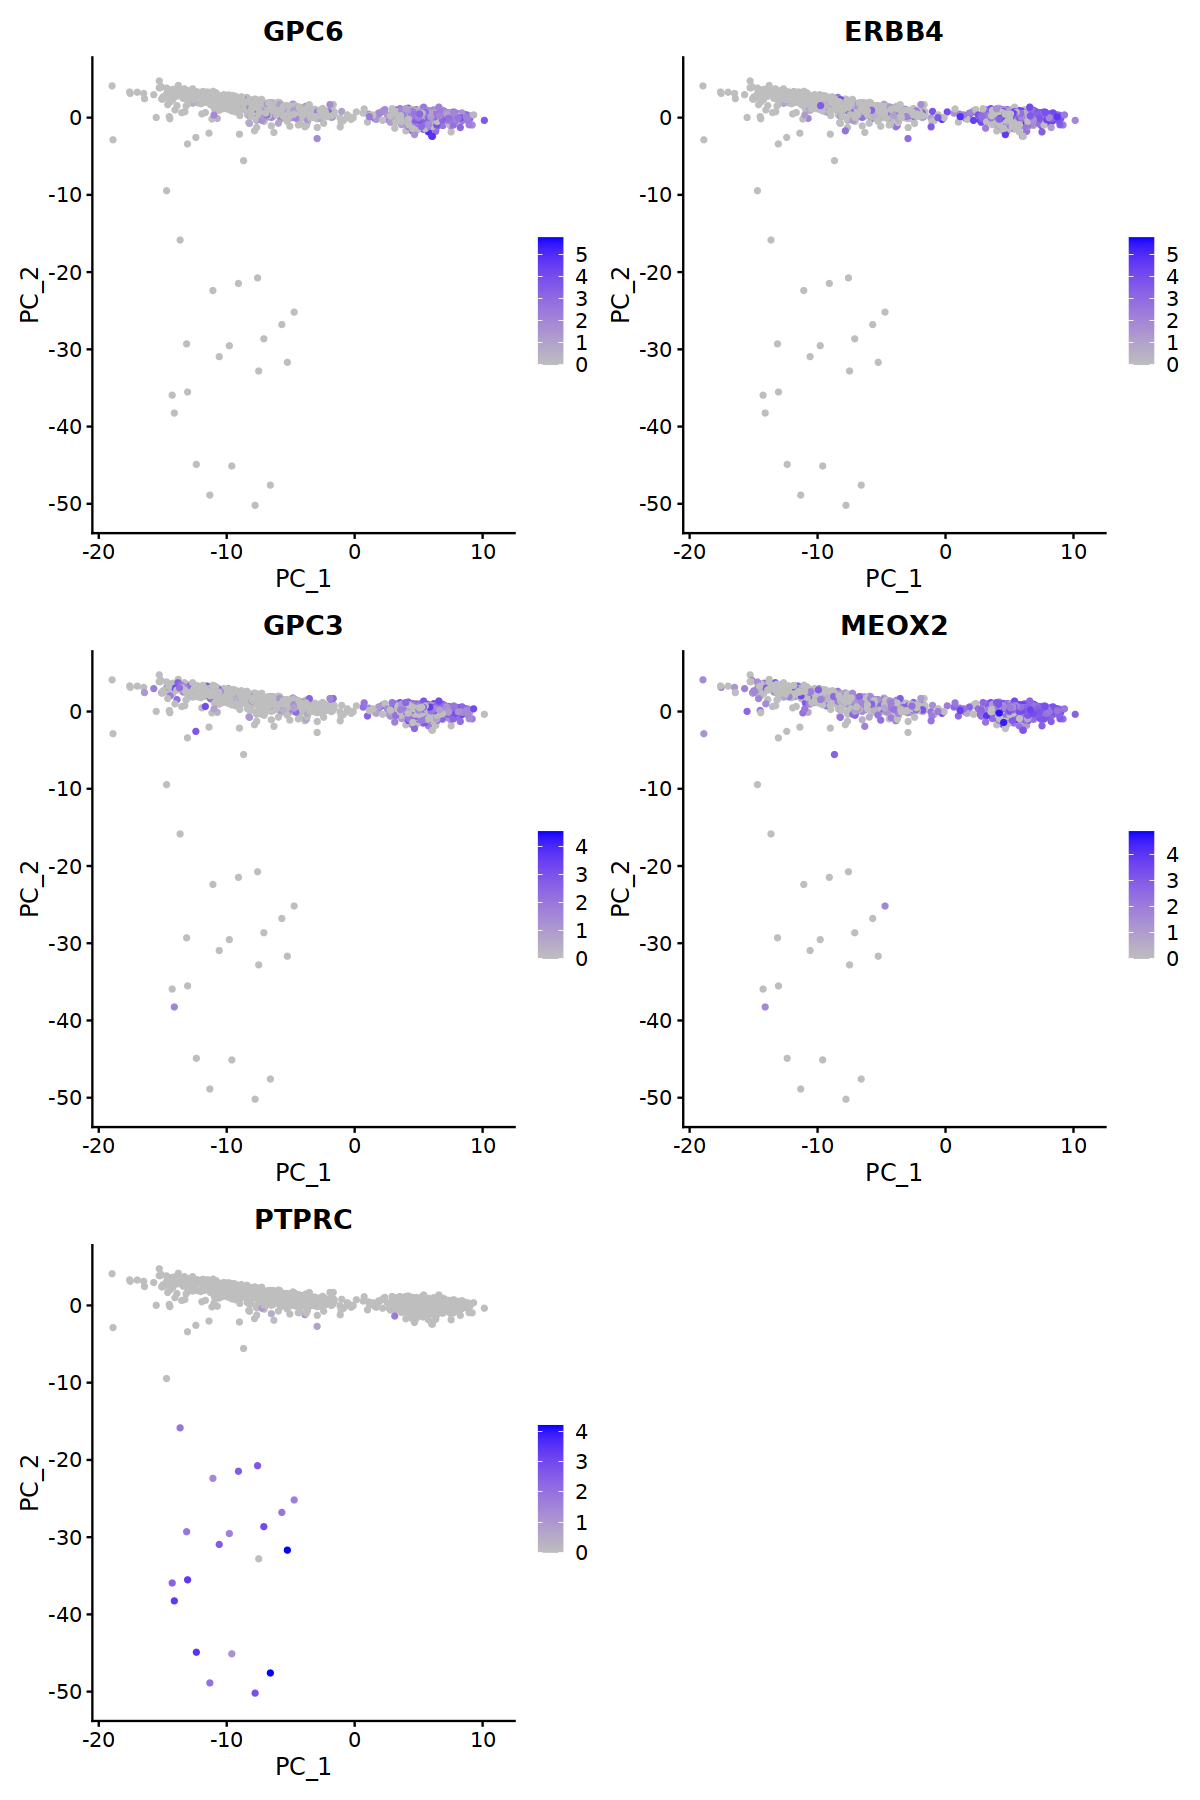

In [20]:
options(repr.plot.width = 10, repr.plot.height = 15)
FeaturePlot(seurat_obj, reduction = "pca", 
            feature=markers, ncol=2,
            cols = c("gray", "blue"),  min.cutoff = 0)

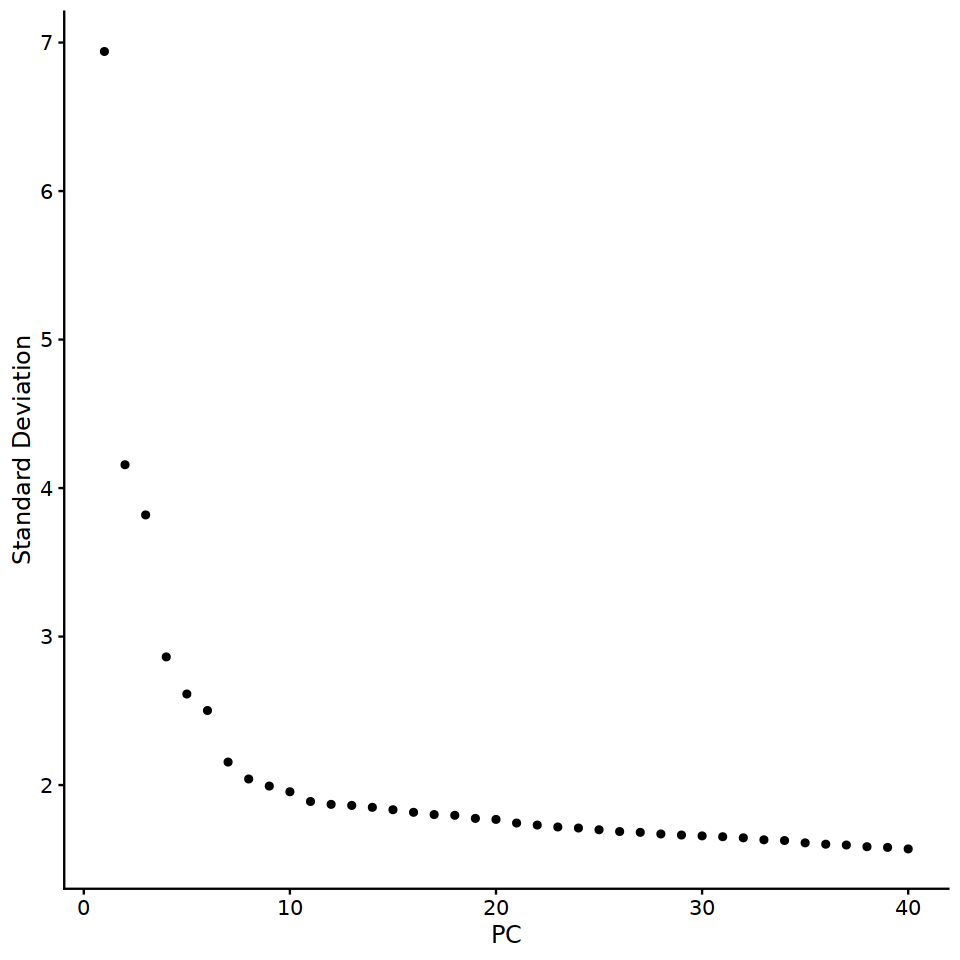

In [21]:
options(repr.plot.width = 8, repr.plot.height = 8)
ElbowPlot(seurat_obj, n=40)

In [22]:
seurat_obj <- RunUMAP(
  seurat_obj,
  dims = 1:20,
  reduction = "pca",
  reduction.key = "rnaUMAP_",
   assay.use = assay_ch,
)

Suggested parameter: assay instead of assay.use


14:10:23 UMAP embedding parameters a = 0.9922 b = 1.112

14:10:23 Read 1504 rows and found 20 numeric columns

14:10:23 Using Annoy for neighbor search, n_neighbors = 30

14:10:23 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:10:23 Writing NN index file to temp file /scratch_tmp/49729482/RtmpR1H1Ka/file91f0365e1111

14:10:23 Searching Annoy index using 1 thread, search_k = 3000

14:10:23 Annoy recall = 100%

14:10:24 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

14:10:26 Initializing from normalized Laplacian + noise (using irlba)

14:10:26 Commencing optimization for 500 epochs, with 60024 positive edges

14:10:31 Optimization finished



In [23]:
seurat_obj <- FindMultiModalNeighbors(
 seurat_obj,
 reduction.list = list("pca", "lsi.atac"),
 dims.list = list(1:20, dcomp$atac)
)

Calculating cell-specific modality weights

Finding 20 nearest neighbors for each modality.

Calculating kernel bandwidths

Finding multimodal neighbors

Constructing multimodal KNN graph

Constructing multimodal SNN graph



In [24]:
seurat_obj <- RunUMAP(
   seurat_obj,
   nn.name = "weighted.nn",
   reduction.name = "wnn.umap",
   reduction.key = "wnnUMAP_"
)

14:10:35 UMAP embedding parameters a = 0.9922 b = 1.112

14:10:36 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 20

14:10:37 Initializing from normalized Laplacian + noise (using irlba)

14:10:37 Commencing optimization for 500 epochs, with 43014 positive edges

14:10:43 Optimization finished



In [25]:
seurat_obj <- Seurat::FindClusters(seurat_obj, resolution = as.numeric(reso),
                                     graph.name = "wsnn")

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 1504
Number of edges: 55461

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9002
Number of communities: 6
Elapsed time: 0 seconds


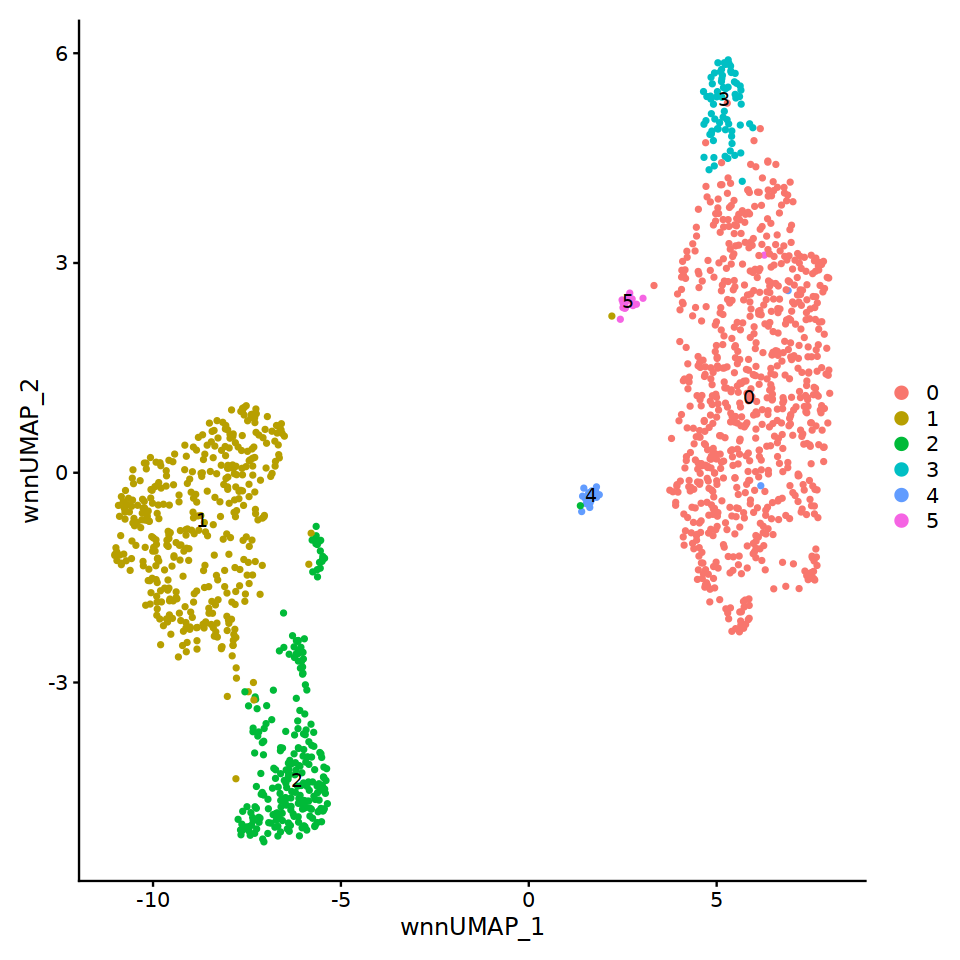

In [26]:
DimPlot(seurat_obj, reduction = "wnn.umap", label=T) 

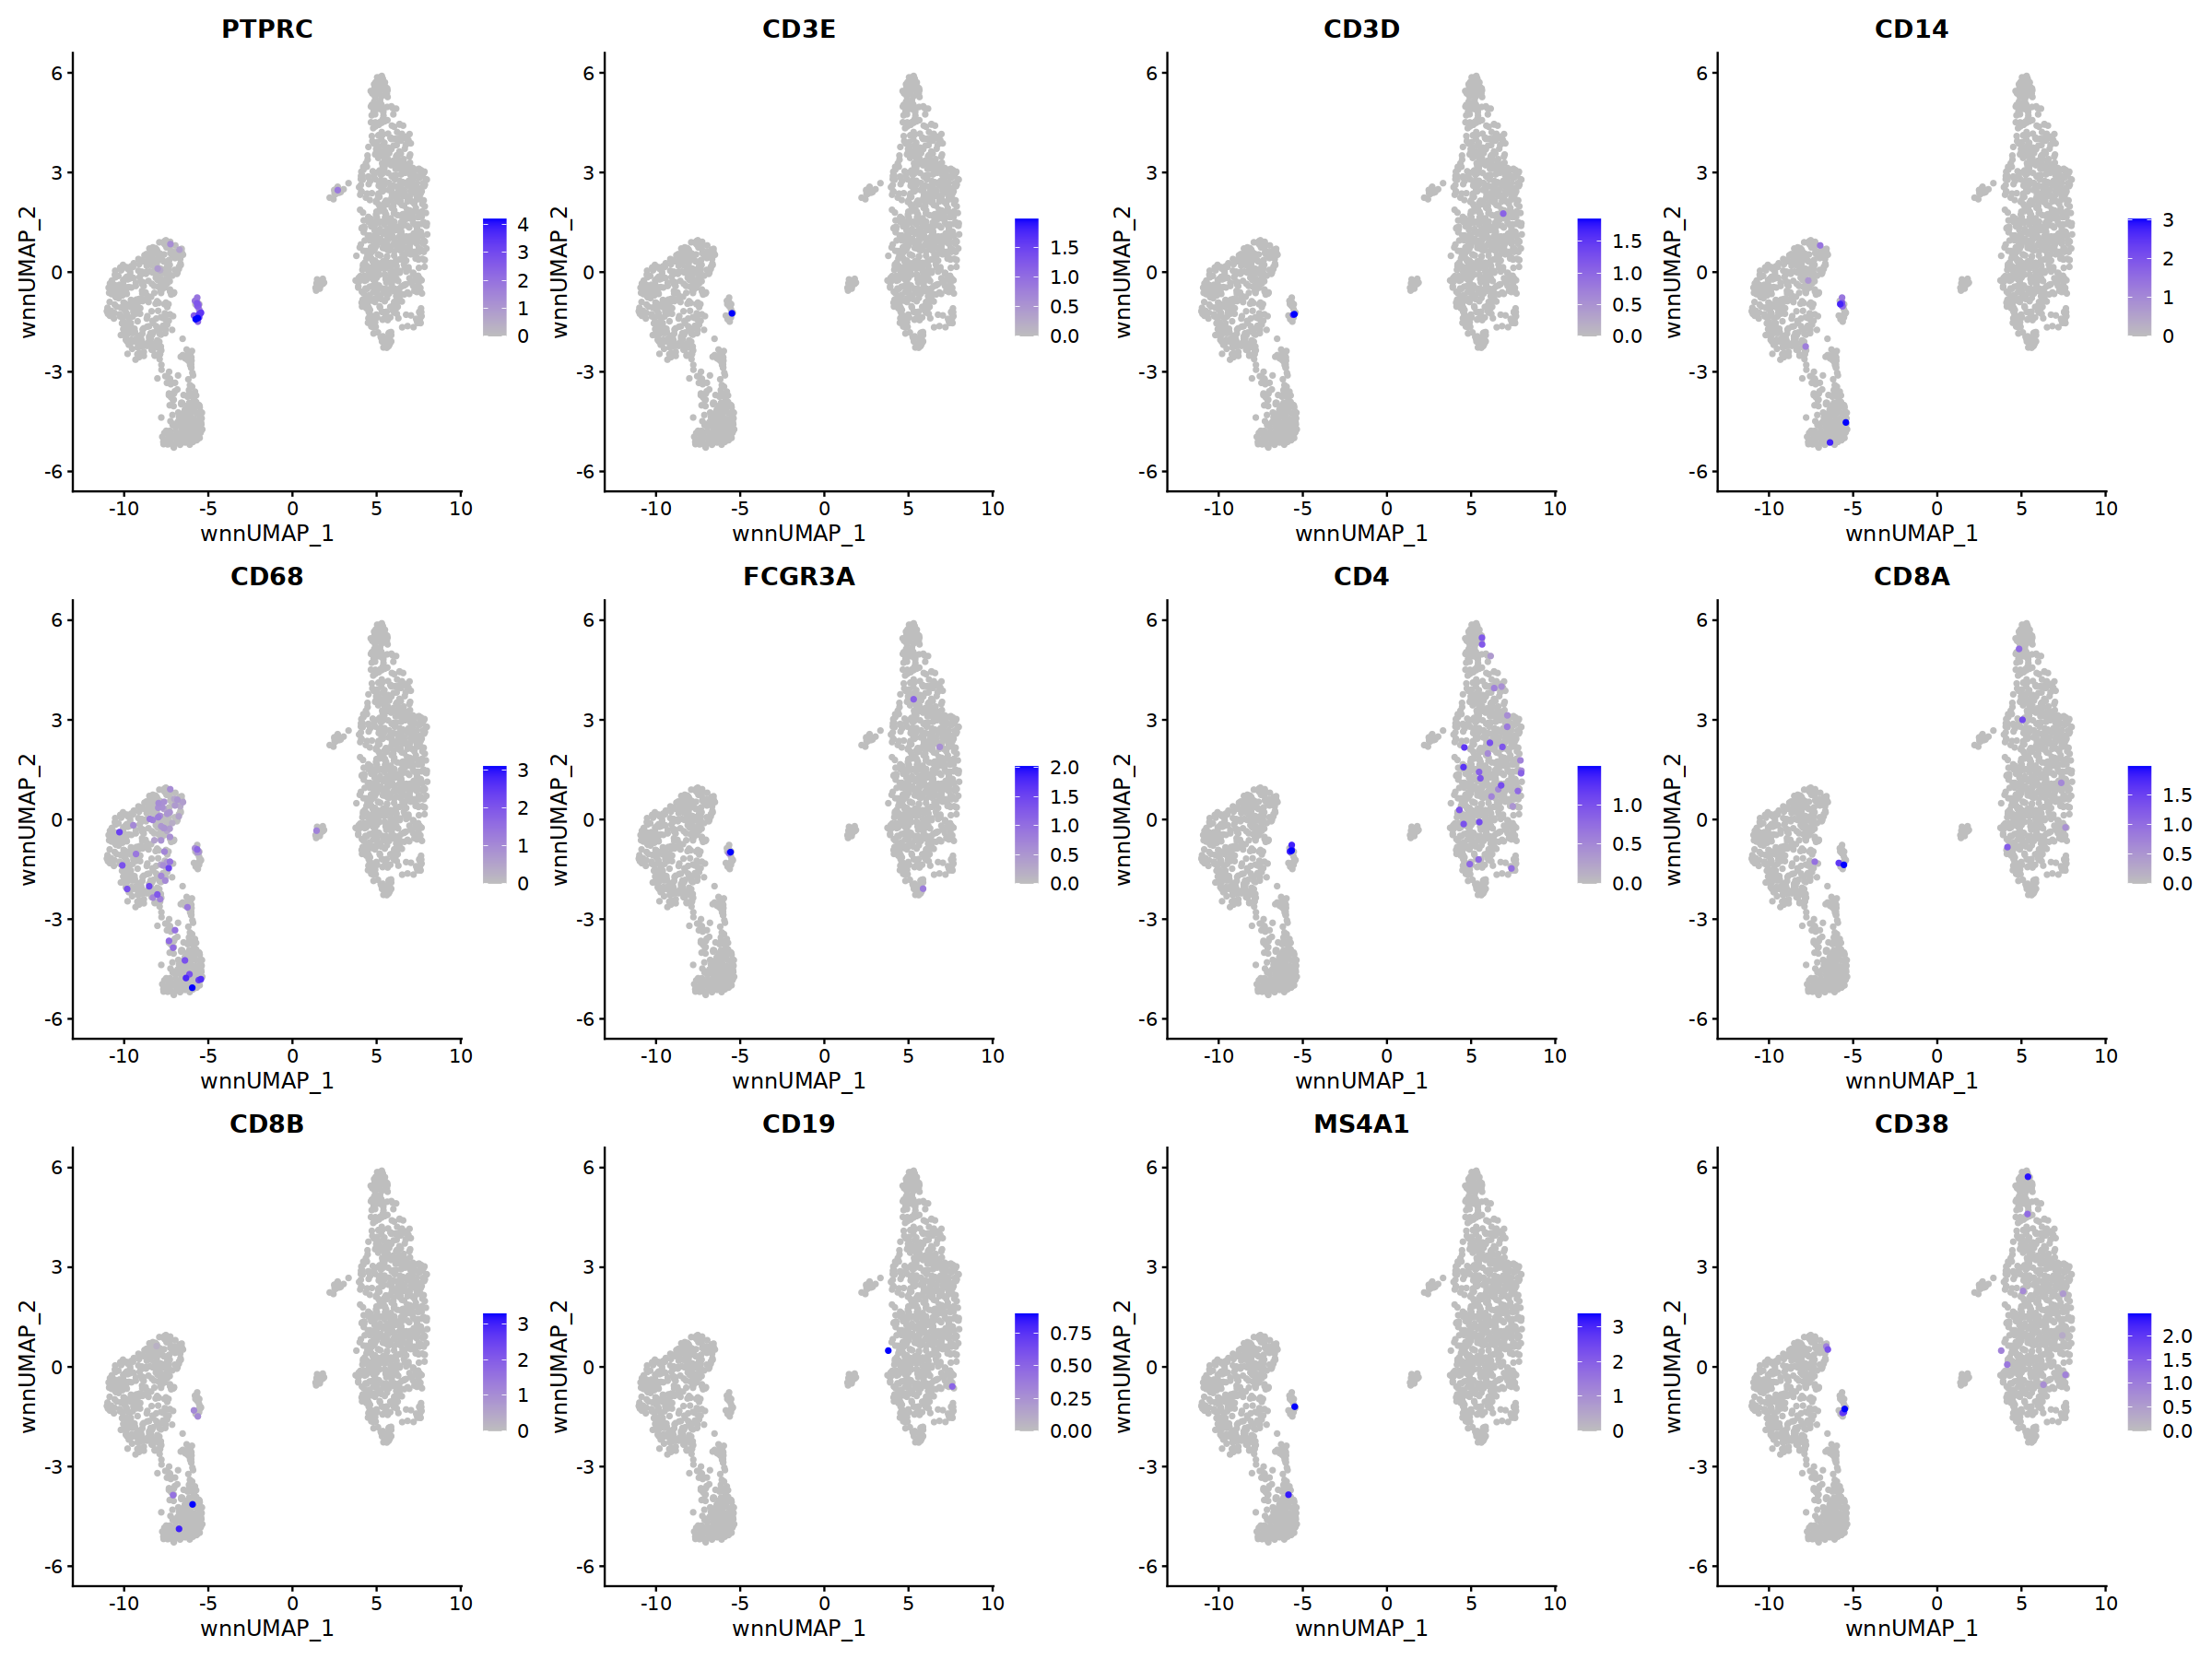

In [27]:
options(repr.plot.width = 20, repr.plot.height = 15)
immune <- c("PTPRC","CD3E", "CD3D", "CD14", "CD68", "FCGR3A", "CD4", "CD8A", "CD8B", "CD19", 
            "MS4A1", "CD38")

vars2plot <- exp_genes_plot(immune, seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

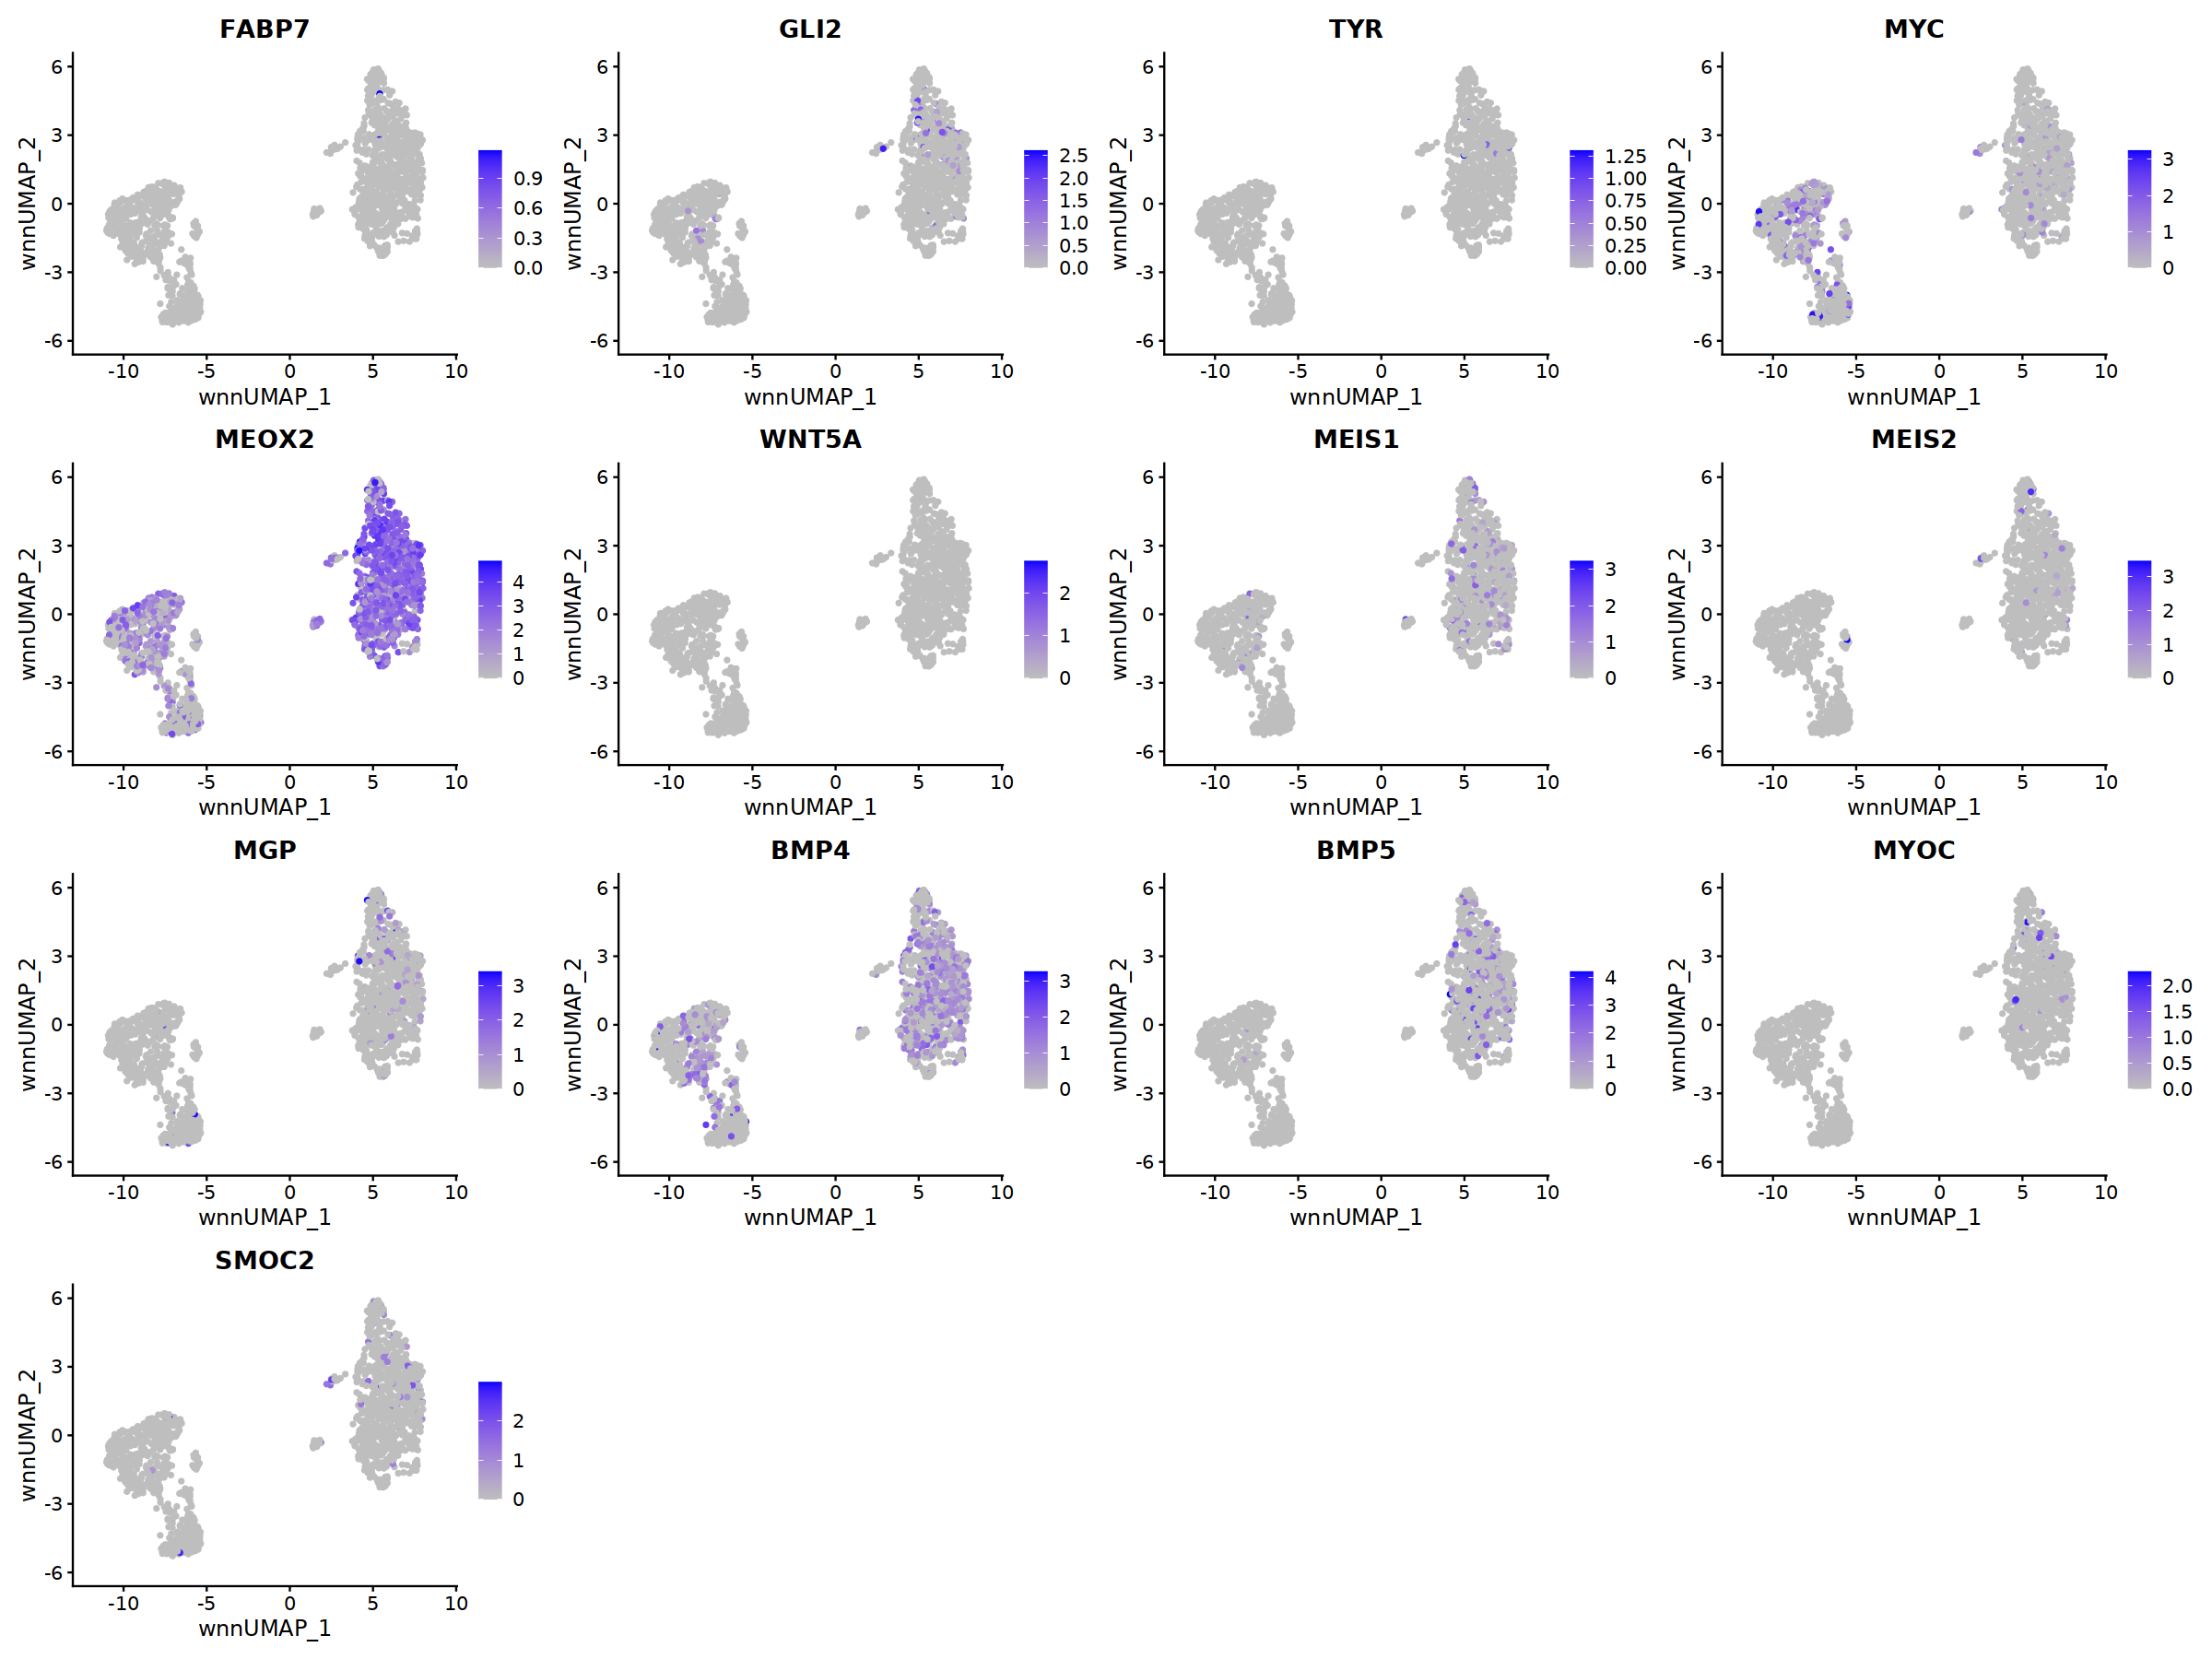

In [28]:
lite_tumor <- c("FABP7", "GLI2", "TYR", "MYC", "MEOX2", "WNT5A", "MEIS1", 
                "MEIS2", "MGP", "BMP4", "BMP5", "MYOC", "SMOC2")

vars2plot <- exp_genes_plot(lite_tumor, seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"),  min.cutoff = 0)

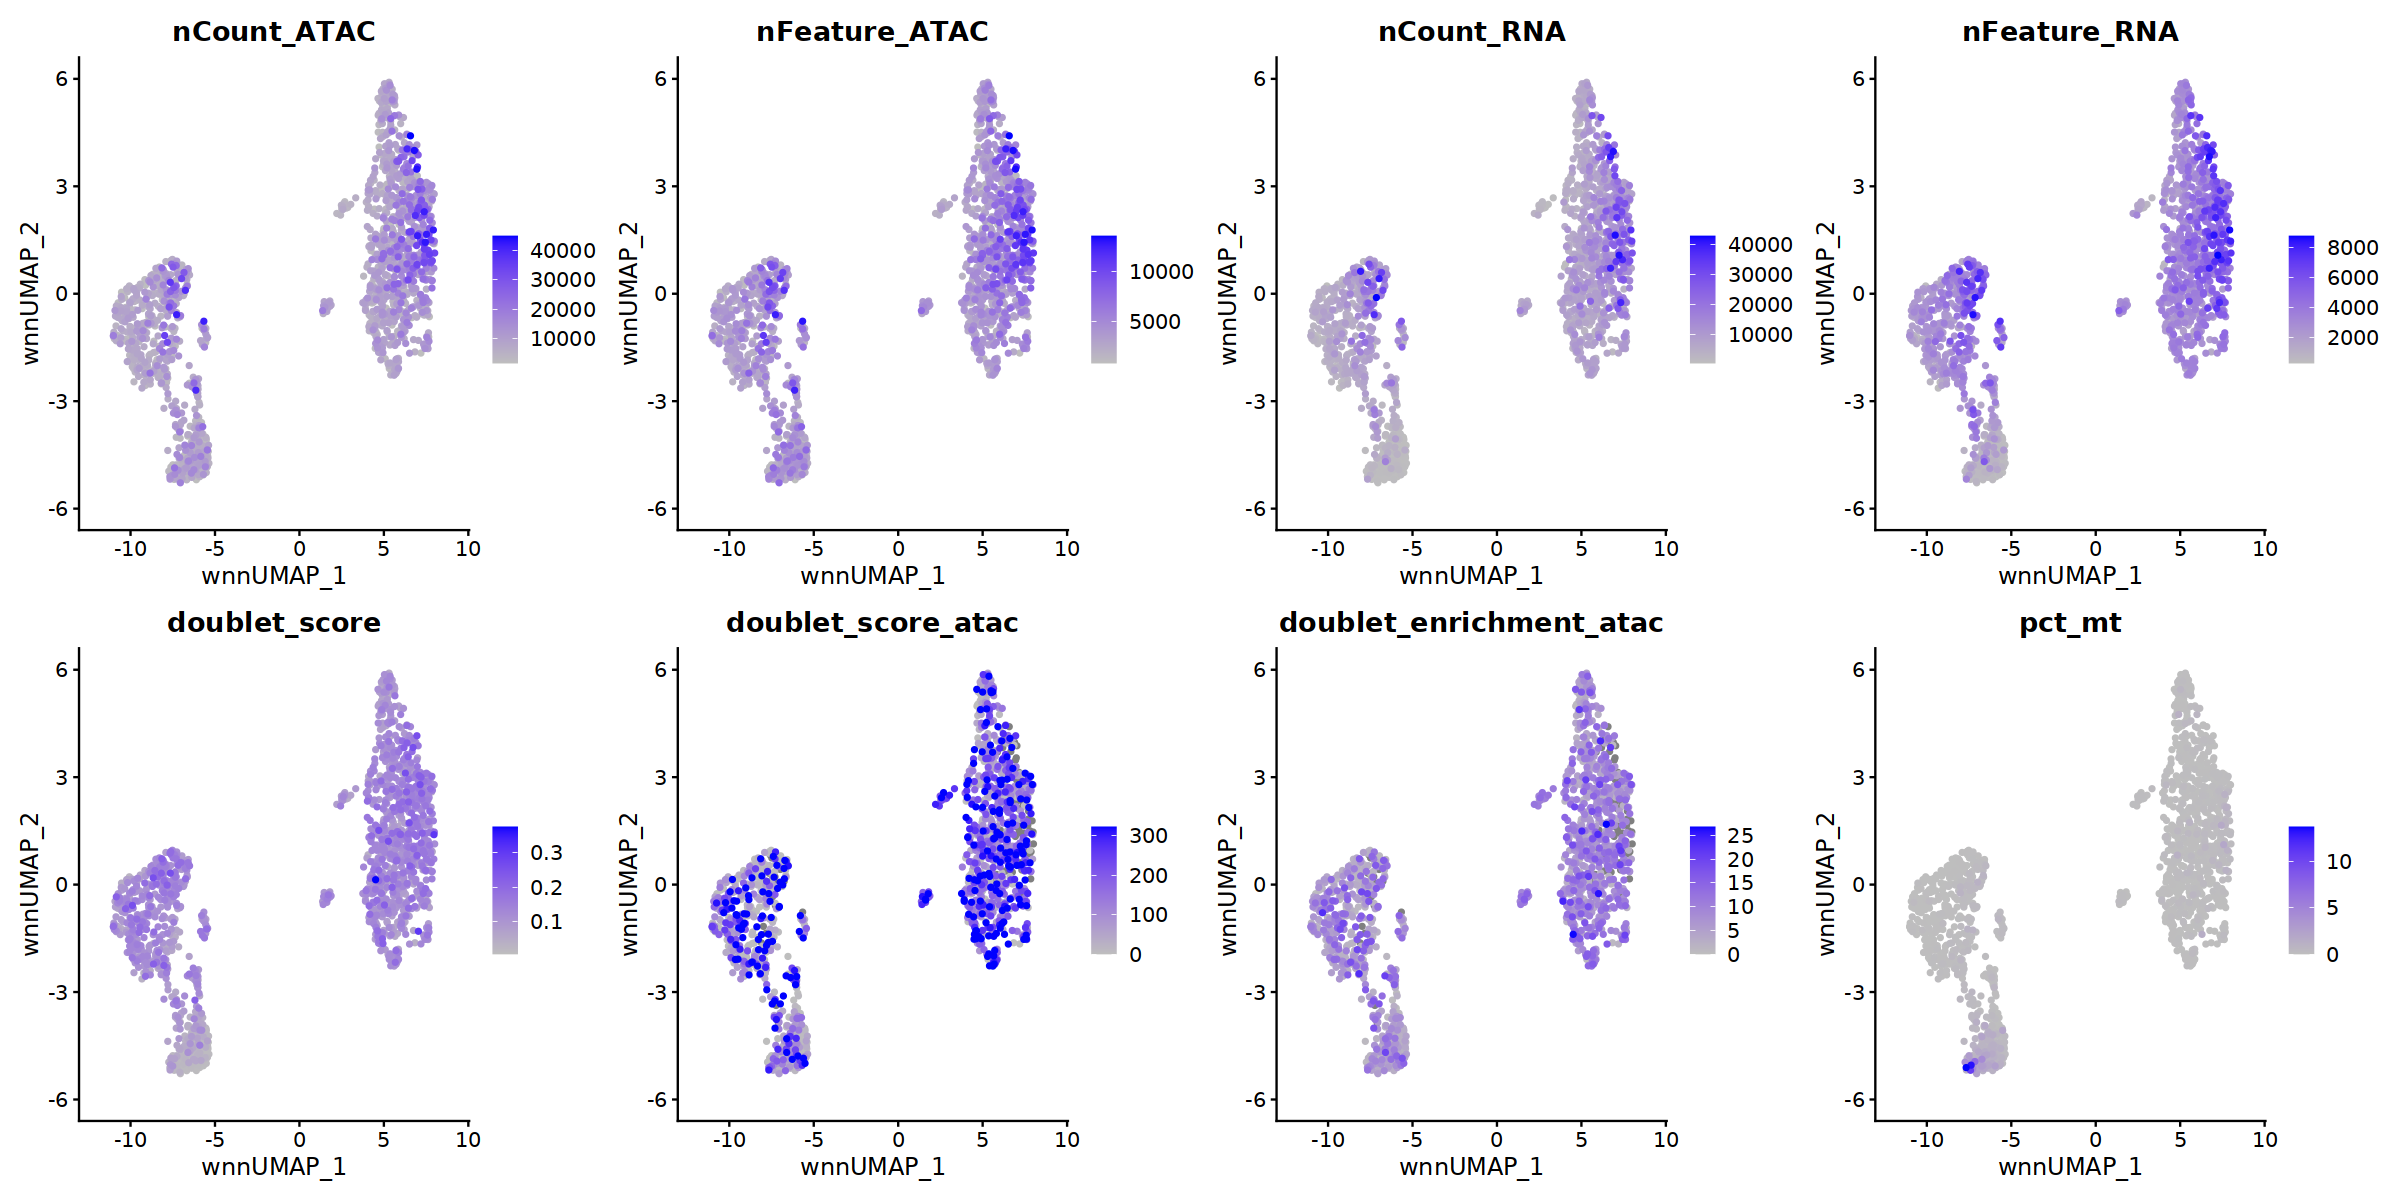

In [29]:
options(repr.plot.width = 20, repr.plot.height = 10)
qc_vars <- c('nCount_ATAC','nFeature_ATAC','nCount_RNA','nFeature_RNA',
             "doublet_score","doublet_score_atac",
             "doublet_enrichment_atac", "pct_mt")


FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=qc_vars, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

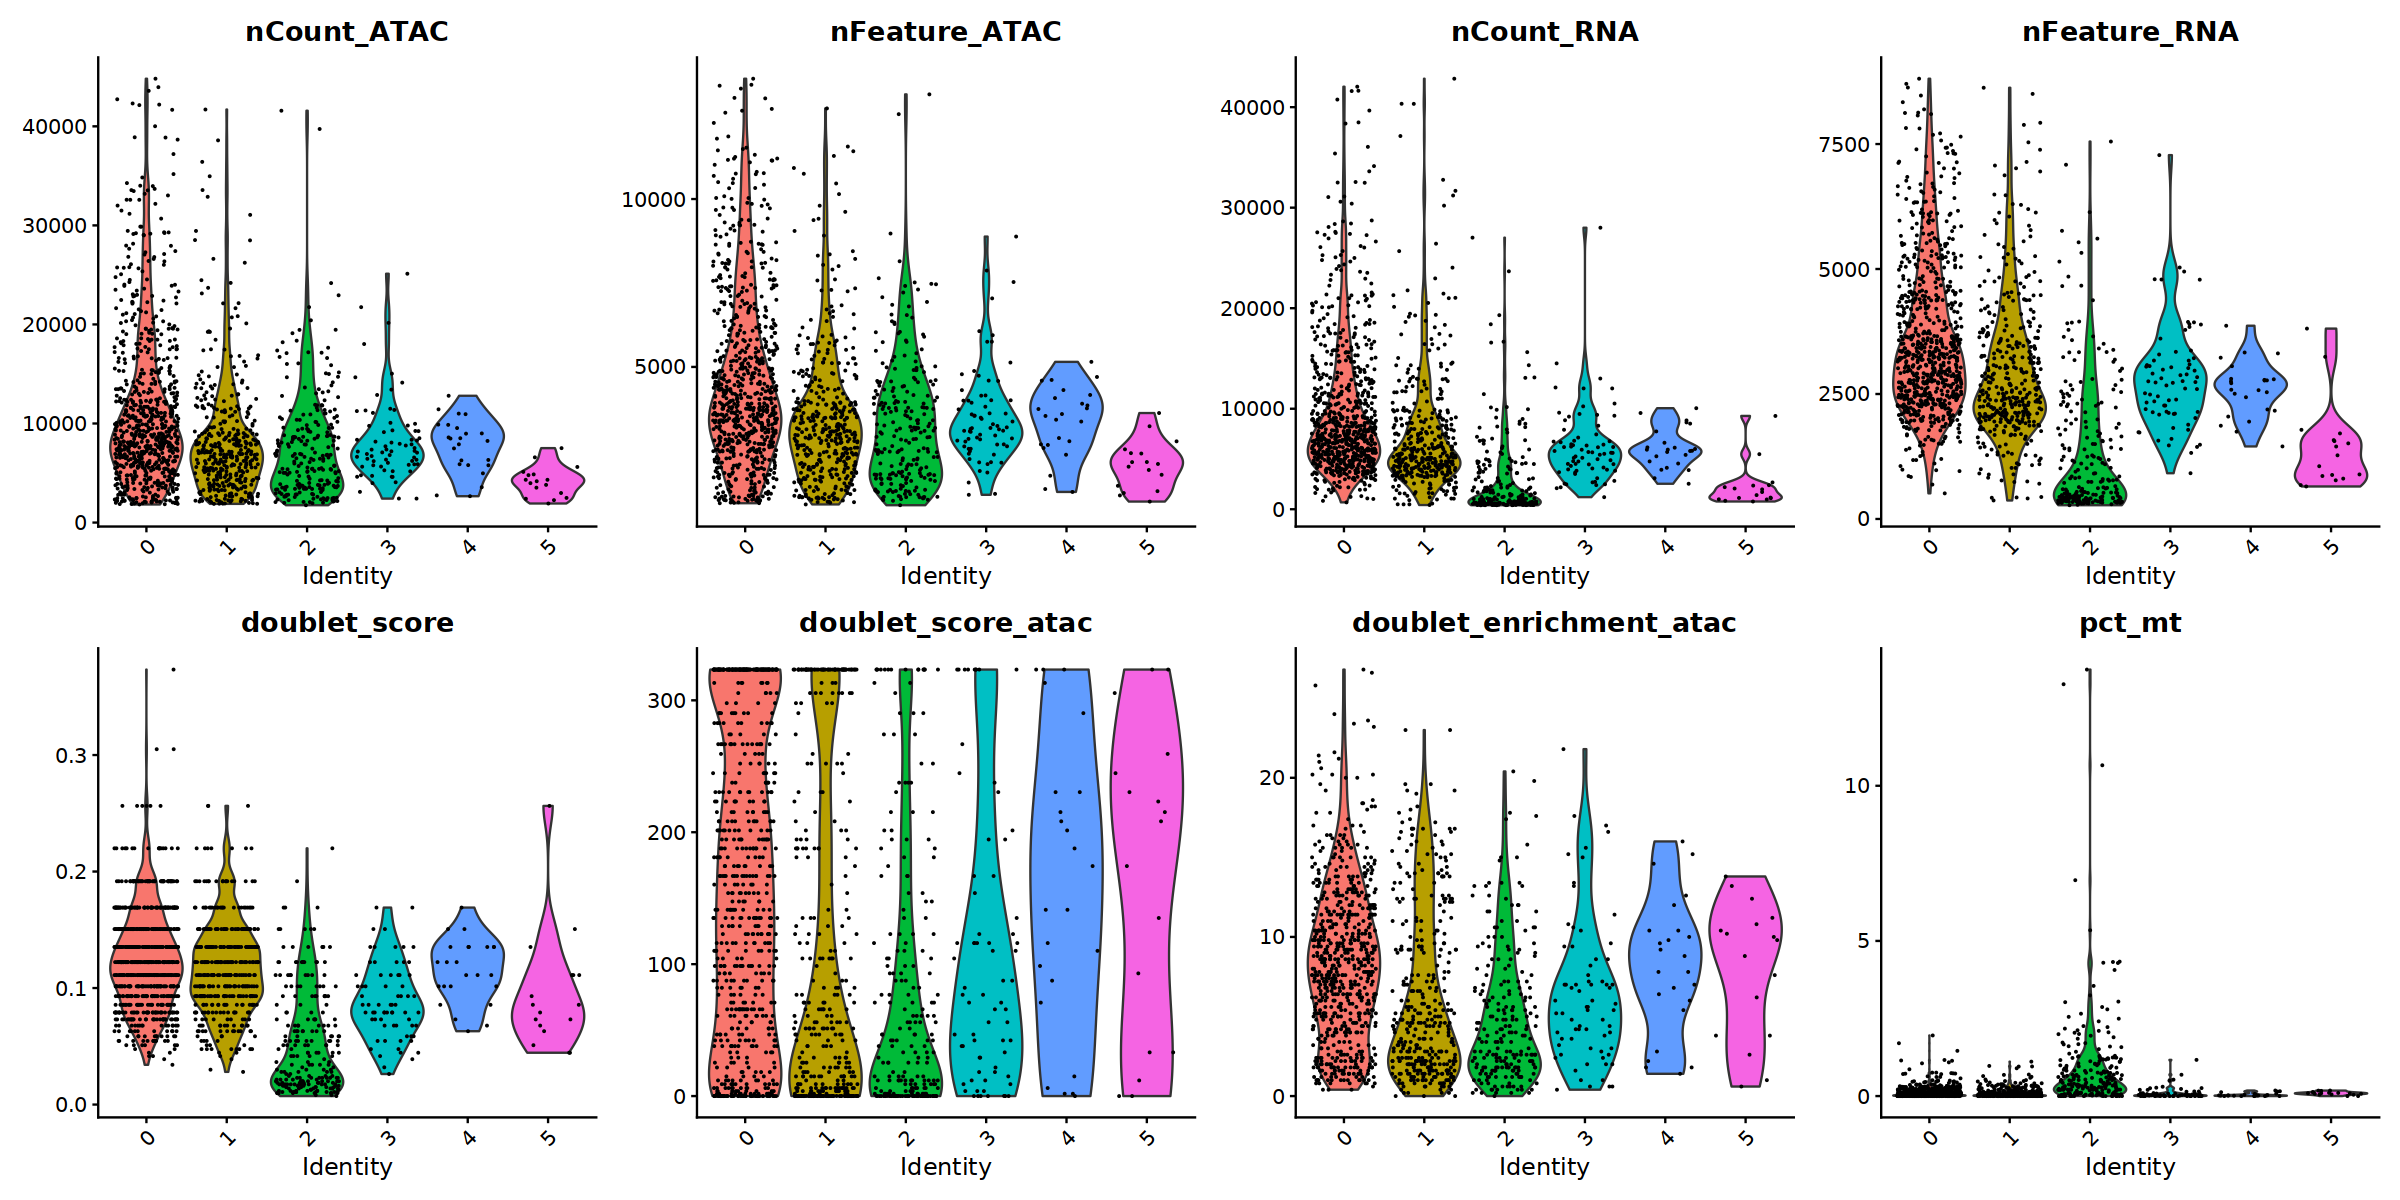

In [30]:
VlnPlot(seurat_obj,feature=qc_vars, ncol = 4)

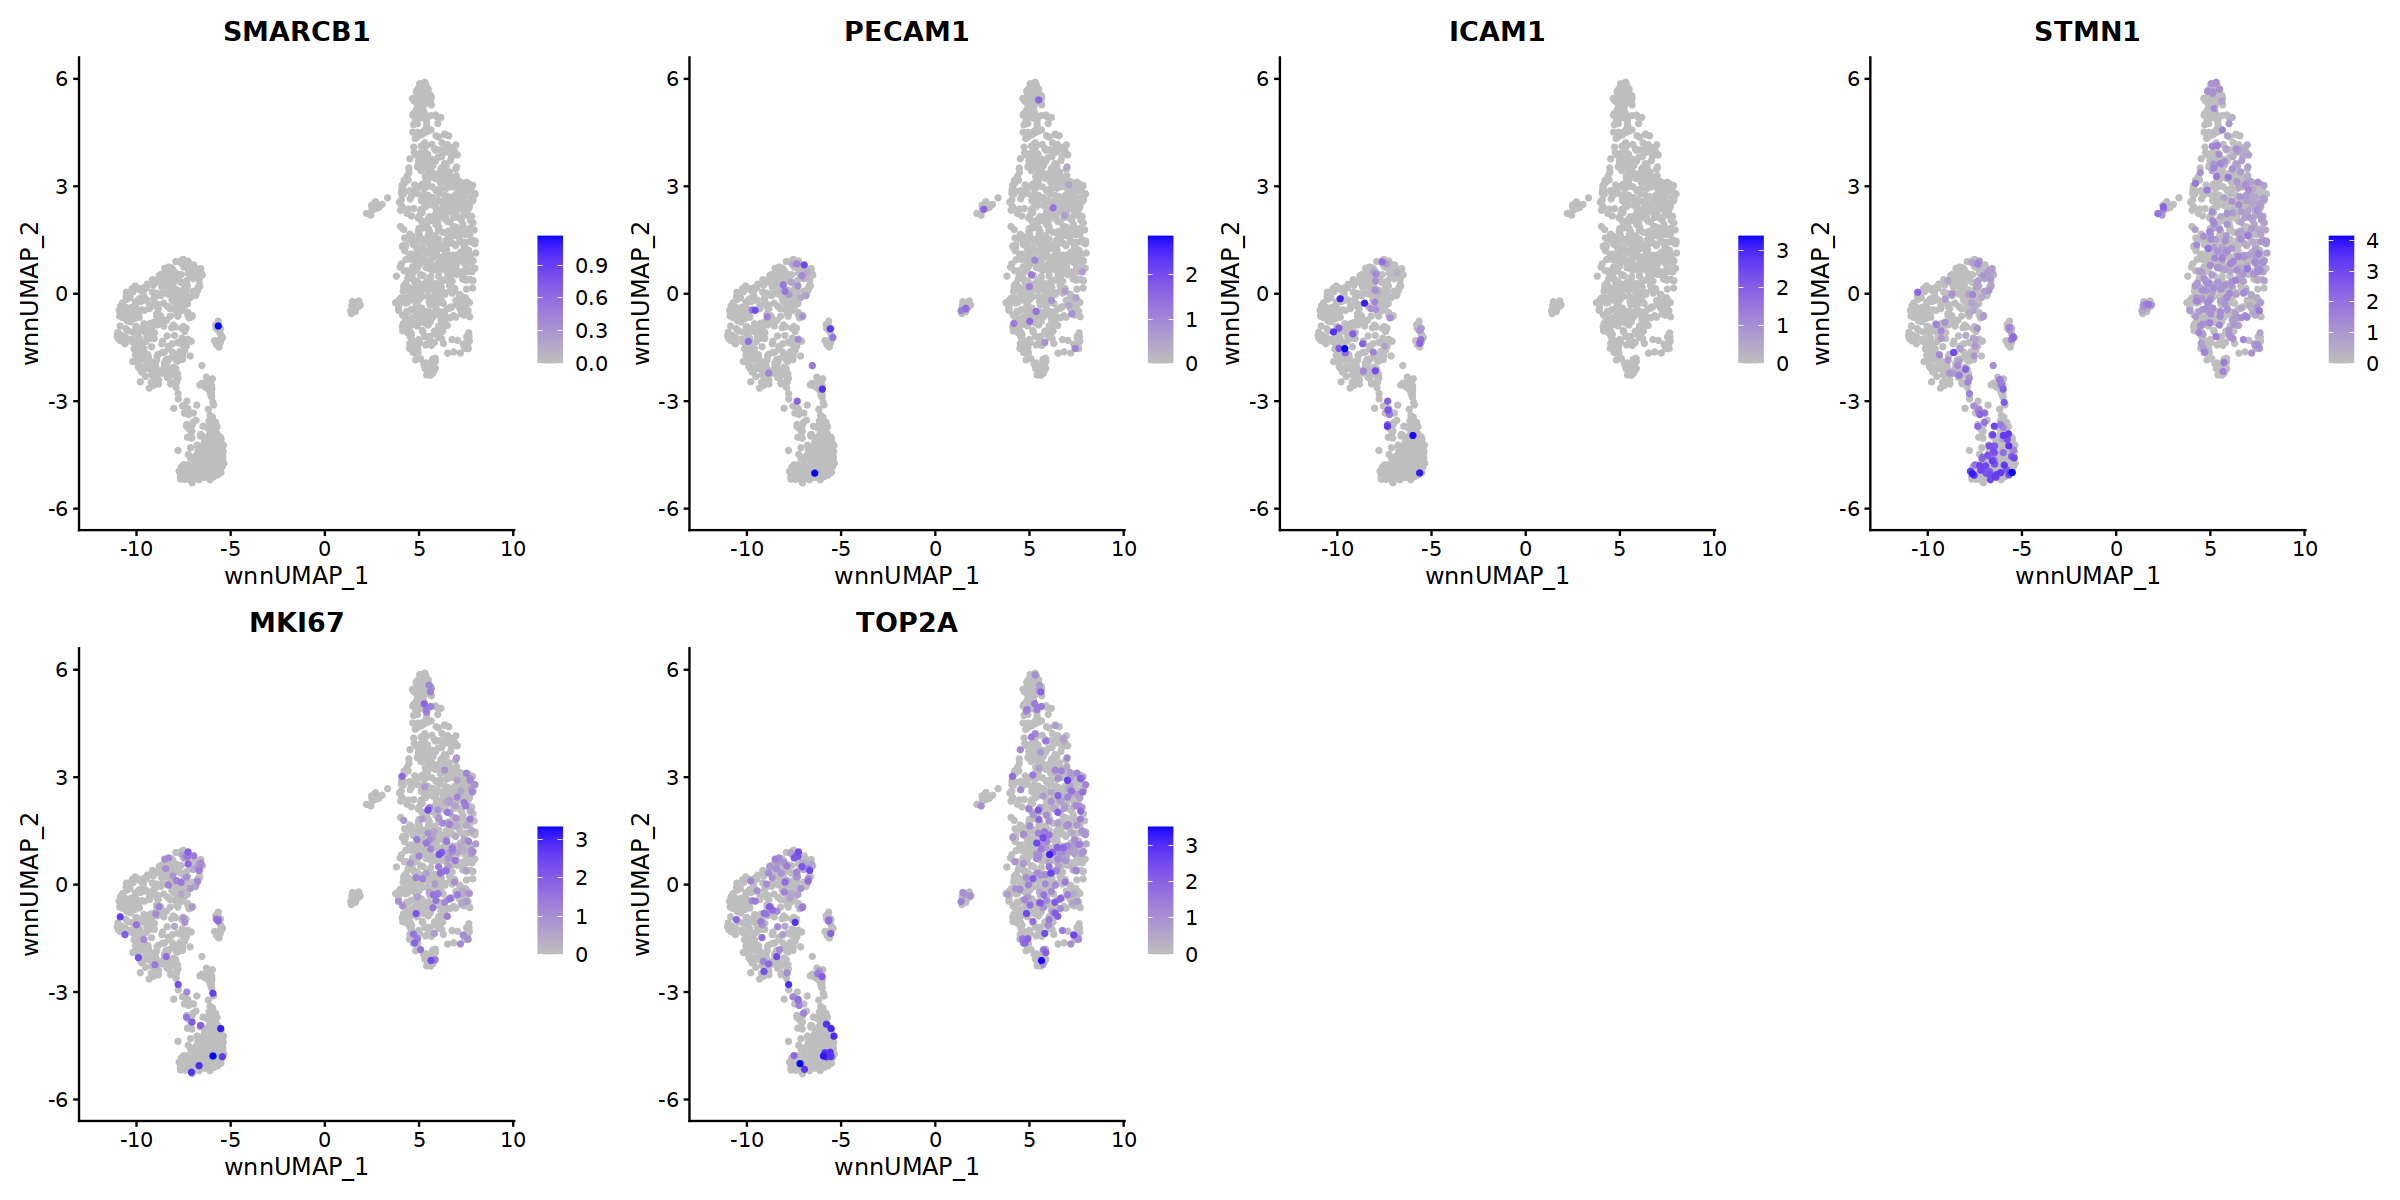

In [31]:
options(repr.plot.width = 20, repr.plot.height = 10)
other <- c("SMARCB1", "PECAM1","ICAM1","STMN1","MKI67","TOP2A")


FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=other, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

In [32]:
seurat_obj <- FindSubCluster(
  seurat_obj,
  cluster=2,
  graph.name = "wsnn",
  subcluster.name = "subclustering",
  resolution = 0.1,
  algorithm = 1
)

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 238
Number of edges: 9837

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9026
Number of communities: 3
Elapsed time: 0 seconds


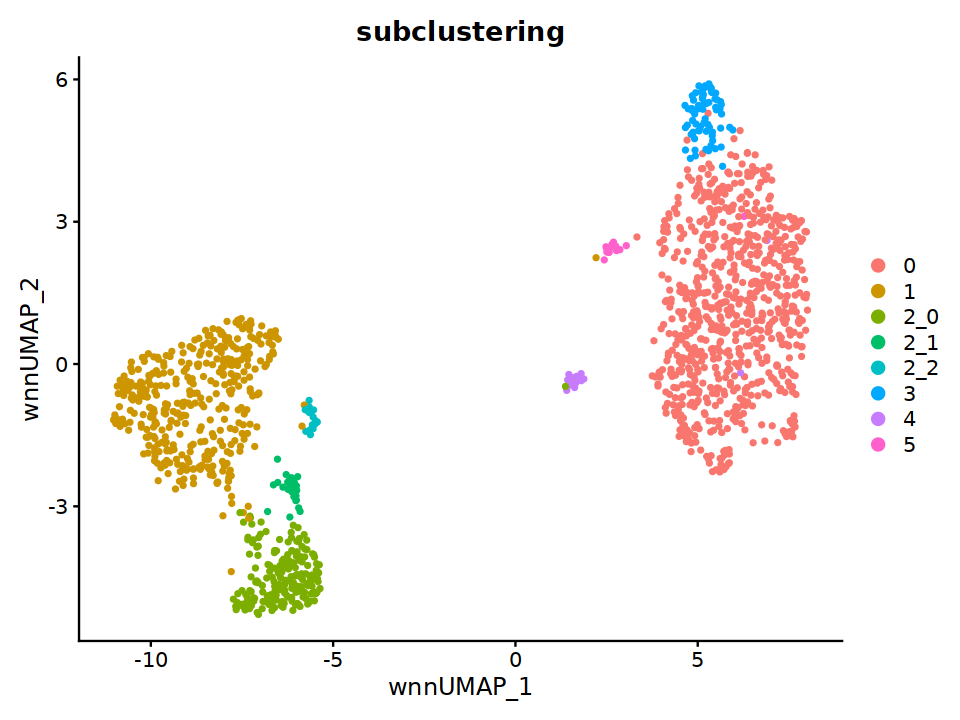

In [33]:
options(repr.plot.width = 8, repr.plot.height = 6)
DimPlot(seurat_obj, reduction = "wnn.umap", group.by = "subclustering")

In [34]:
seurat_obj <- SetIdent(seurat_obj, value=seurat_obj@meta.data$subclustering)

In [35]:
rna.markers <- FindAllMarkers(seurat_obj,only.pos = TRUE, min.pct = 0.1, logfc.threshold = 0.2)

Calculating cluster 1

Calculating cluster 2_0

Calculating cluster 5

Calculating cluster 0

Calculating cluster 4

Calculating cluster 2_1

Calculating cluster 3

Calculating cluster 2_2



## Filter cells

Cluster 2 low quality cells 

In [36]:
rna.markers %>% 
  dplyr::filter(cluster == "2_0") %>%
  dplyr::filter(p_val_adj<0.05) %>% 
  arrange(desc(avg_log2FC)) %>% head(n=30)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
MTRNR2L12,1.404821e-90,4.226869,0.576,0.074,4.160938e-86,2_0,MTRNR2L12
MT-CO1,5.768809e-49,3.798519,0.759,0.478,1.708664e-44,2_0,MT-CO1
RPL35,3.425705e-70,3.665142,0.843,0.499,1.014659e-65,2_0,RPL35
RPL35A,4.821781e-76,3.623316,0.869,0.517,1.428163e-71,2_0,RPL35A
RPL37A,1.756143e-93,3.608751,0.963,0.804,5.201521e-89,2_0,RPL37A
RPS29,2.806004e-77,3.592343,0.890,0.570,8.311104e-73,2_0,RPS29
RPS27,3.463822e-69,3.573634,0.843,0.506,1.025949e-64,2_0,RPS27
RPS18,5.118844e-81,3.556020,0.921,0.746,1.516150e-76,2_0,RPS18
RPL17,3.362358e-66,3.513465,0.853,0.610,9.958969e-62,2_0,RPL17


In [37]:
rna.markers %>% 
  dplyr::filter(cluster == "2_1") %>%
  dplyr::filter(p_val_adj<0.05) %>% 
  arrange(desc(avg_log2FC)) %>% head(n=30)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
HSPH1,3.647134e-63,5.211362,0.821,0.054,1.080245e-58,2_1,HSPH1
HSP90AA11,3.659290e-17,4.379803,0.929,0.443,1.083845e-12,2_1,HSP90AA1
HSPA1A,2.171724e-46,4.148270,0.643,0.044,6.432431e-42,2_1,HSPA1A
HSPA1B1,4.676899e-66,4.082656,0.714,0.035,1.385251e-61,2_1,HSPA1B
DNAJB61,1.216517e-23,3.127100,0.714,0.127,3.603201e-19,2_1,DNAJB6
CACYBP1,6.462877e-60,3.099552,0.750,0.045,1.914240e-55,2_1,CACYBP
ABHD3,7.192046e-18,3.045127,0.500,0.077,2.130212e-13,2_1,ABHD3
CHORDC11,1.336975e-11,2.953294,0.500,0.122,3.959986e-07,2_1,CHORDC1
HSPD1,7.437974e-12,2.892165,0.821,0.427,2.203053e-07,2_1,HSPD1


Remove low quality cells and doublets from object

In [38]:
seurat_obj <- subset(seurat_obj, ident=c("2_0", "2_1"), invert=T)

## Re-process object after filtering

### RNA

In [39]:
DefaultAssay(seurat_obj) <- assay_ch
seurat_obj <- NormalizeData(
  seurat_obj,
  normalization.method = "LogNormalize",
  scale.factor = 1e4
)

In [40]:
# compute the variance and mean of the log-expression values 
sce <- as.SingleCellExperiment(seurat_obj)
gene_var <- modelGeneVar(sce)

tops <- gene_var %>% 
    as.data.frame() %>% 
    arrange(desc(total)) %>% 
    head(n=20)

plt <- gene_var %>% 
  as.data.frame() %>% 
  ggplot(aes(mean, total)) +
  geom_point() +
  geom_line(aes(y = tech), colour = "dodgerblue", size = 1) +
  labs(x = "Mean of log-expression", y = "Variance of log-expression")+
  geom_text(data=tops, aes(mean,total,label=rownames(tops)))

hvgs <- getTopHVGs(gene_var,fdr.threshold = 0.05)

In [41]:
sce

class: SingleCellExperiment 
dim: 29619 1285 
metadata(0):
assays(2): counts logcounts
rownames(29619): AL627309.1 AL627309.3 ... AC007325.4 AC007325.2
rowData names(0):
colnames(1285): AAACAGCCAGACAAAC-1 AAACCGAAGGCAGGTG-1 ...
  TTTGTCTAGGTCTTGG-1 TTTGTTGGTGTTTGCT-1
colData names(39): orig.ident nCount_ATAC ... subclustering ident
reducedDimNames(3): PCA UMAP WNN.UMAP
mainExpName: RNA_decontx
altExpNames(2): RNA ATAC

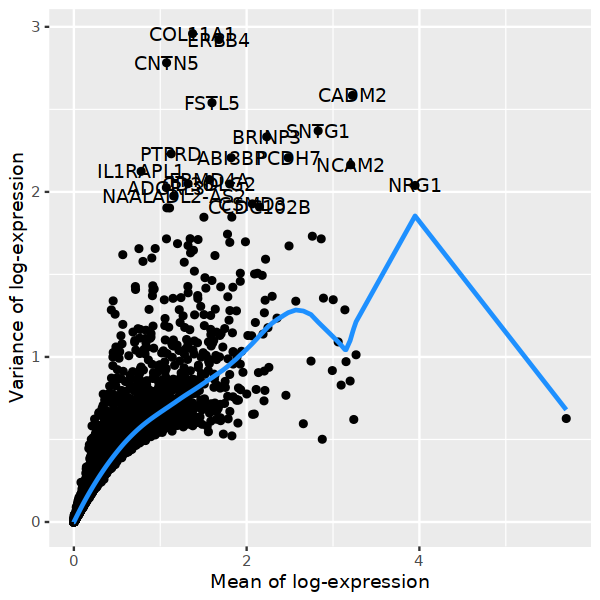

In [42]:
options(repr.plot.width = 5, repr.plot.height = 5)
plt

In [43]:
VariableFeatures(seurat_obj) <- hvgs

seurat_obj <- seurat_obj %>%
  ScaleData() %>% 
  RunPCA() 

Centering and scaling data matrix

PC_ 1 
Positive:  DOK6, CADM2, ABI3BP, PCDH7, BRINP3, CSMD3, LRRTM3, PLEKHA5, SNTG1, NCOA1 
	   KCNMB2, SVEP1, FRMD4A, TCF4, GPC3, AL354771.1, FN1, CALCRL, DLG2, NCAM2 
	   GAS2, PTPRD, PXDNL, TMEFF2, LINC00882, HGF, CCDC178, BMPR1B, TENM1, CCDC102B 
Negative:  ANXA2, ERRFI1, ADAM9, CAPN2, ITGB1, TM4SF1, EMP1, SRGAP1, AHNAK, ERO1A 
	   VIM, ESYT2, TRIO, FTL, MYOF, OSBP2, ANXA1, SLC2A3, SMURF2, PPL 
	   HK2, SLC4A7, SLC2A1, ANKRD28, HSPA5, TIMP1, SERPINE1, PLCG2, FGFR1, TES 
PC_ 2 
Positive:  MYOF, ERRFI1, ESYT2, EMP1, AHNAK, TM4SF1, SERPINE1, OSBP2, PPL, ANKRD28 
	   SLC20A1, SMURF2, TRIO, ANXA2, ERO1A, FGFR1, SRGAP1, NCAM2, CAPN2, TIMP3 
	   ARHGAP29, RRAS2, ADAM9, KCNH1, MATN3, ANGPTL4, PDZRN4, LGI4, NCEH1, SLC2A1 
Negative:  PTPRC, DOCK8, DOCK2, IKZF1, ATXN1, APBB1IP, FYB1, CD53, CHST11, LCP2 
	   AOAH, SKAP1, VAV3, SRGN, GPRIN3, SYK, SFMBT2, SLA, GNG2, BIN2 
	   CD247, MDFIC, TOX, ITGA4, PAG1, C22orf34, ARAP2, CD96, LINC00299, ARHGAP25 
PC_ 3 
Pos

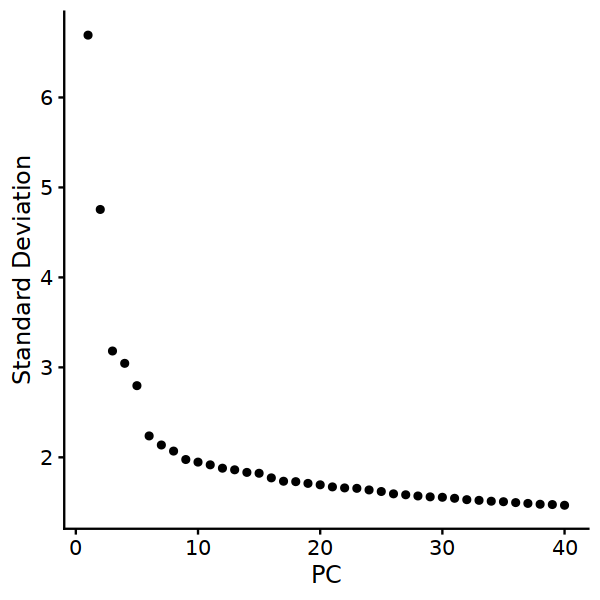

In [44]:
ElbowPlot(seurat_obj, n=40)

### ATAC

In [45]:
DefaultAssay(seurat_obj) <- "ATAC" # for individual analysis
seurat_obj <- RunTFIDF(seurat_obj)

Performing TF-IDF normalization



In [46]:
seurat_obj <- FindTopFeatures(seurat_obj, min.cutoff = "q75")
seurat_obj <- RunSVD(seurat_obj, reduction.name = "lsi.atac")

Running SVD

Scaling cell embeddings



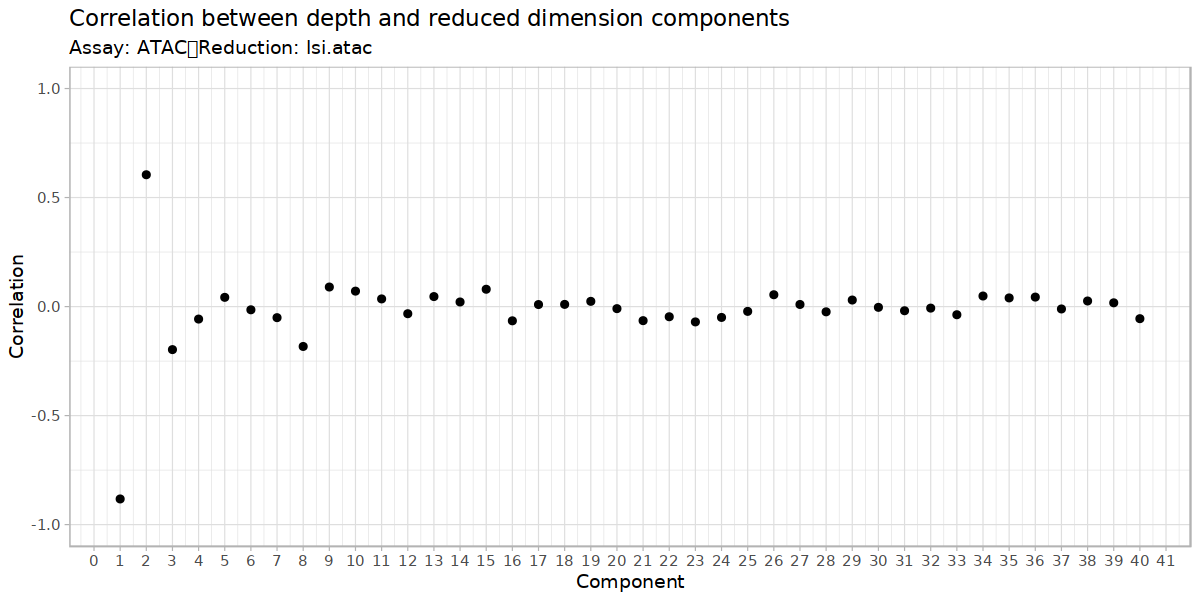

In [47]:
options(repr.plot.width = 10, repr.plot.height = 5)
DepthCor(seurat_obj, reduction = "lsi.atac", n=40)

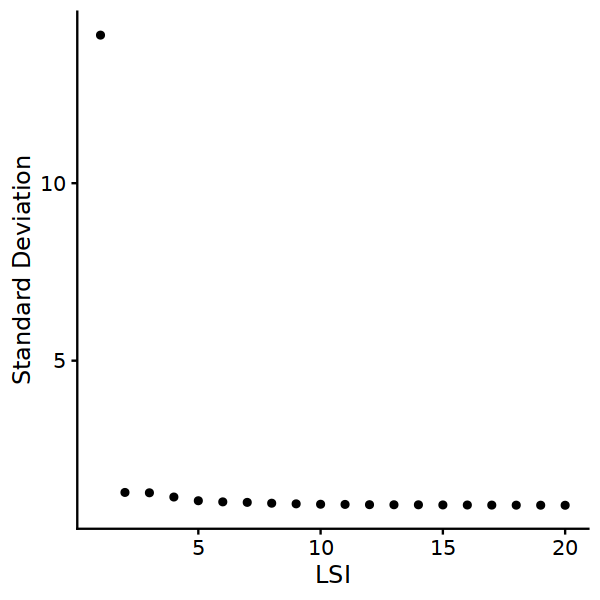

In [48]:
options(repr.plot.width = 5, repr.plot.height = 5)
ElbowPlot(seurat_obj, n=20, reduction="lsi.atac")

### Joint

In [49]:
seurat_obj <- FindMultiModalNeighbors(
 seurat_obj,
 reduction.list = list("pca", "lsi.atac"),
 dims.list = list(1:20, dcomp$atac)
)

Calculating cell-specific modality weights

Finding 20 nearest neighbors for each modality.

Calculating kernel bandwidths

Finding multimodal neighbors

Constructing multimodal KNN graph

Constructing multimodal SNN graph



In [50]:
DefaultAssay(seurat_obj) <- assay_ch
seurat_obj <- RunUMAP(
   seurat_obj,
   nn.name = "weighted.nn",
   reduction.name = "wnn.umap",
   reduction.key = "wnnUMAP_"
)

14:12:44 UMAP embedding parameters a = 0.9922 b = 1.112

14:12:45 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 20

14:12:46 Initializing from normalized Laplacian + noise (using irlba)

14:12:46 Commencing optimization for 500 epochs, with 35478 positive edges

14:12:50 Optimization finished



In [51]:
seurat_obj <- Seurat::FindClusters(seurat_obj, resolution = 0.1,
                                     graph.name = "wsnn")

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 1285
Number of edges: 41761

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9507
Number of communities: 4
Elapsed time: 0 seconds


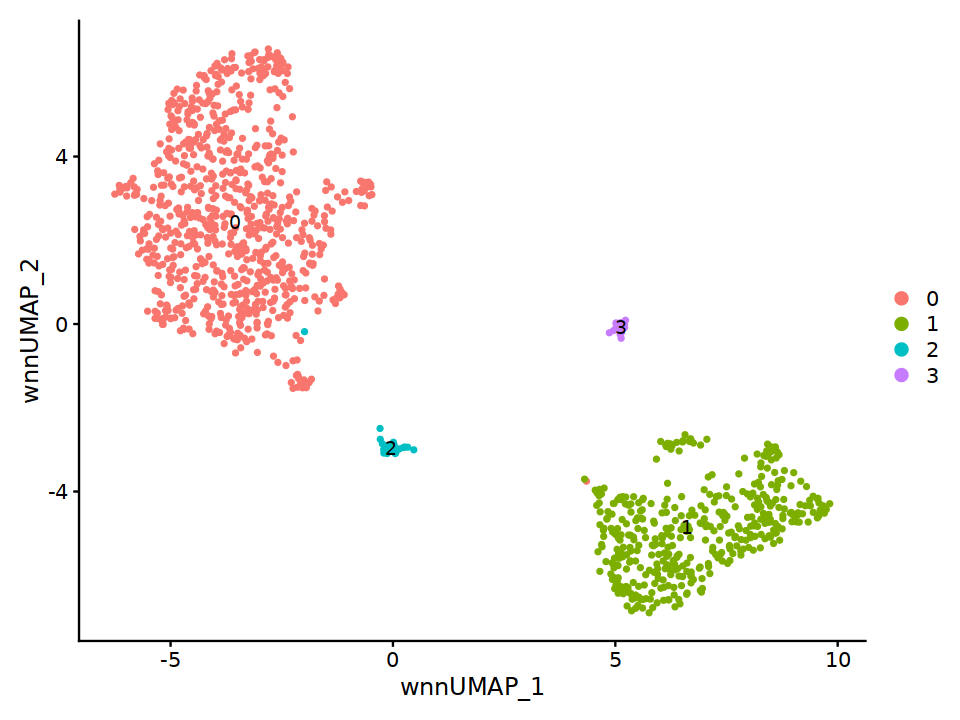

In [52]:
options(repr.plot.width = 8, repr.plot.height = 6)
DimPlot(seurat_obj, reduction = "wnn.umap", label=T) 

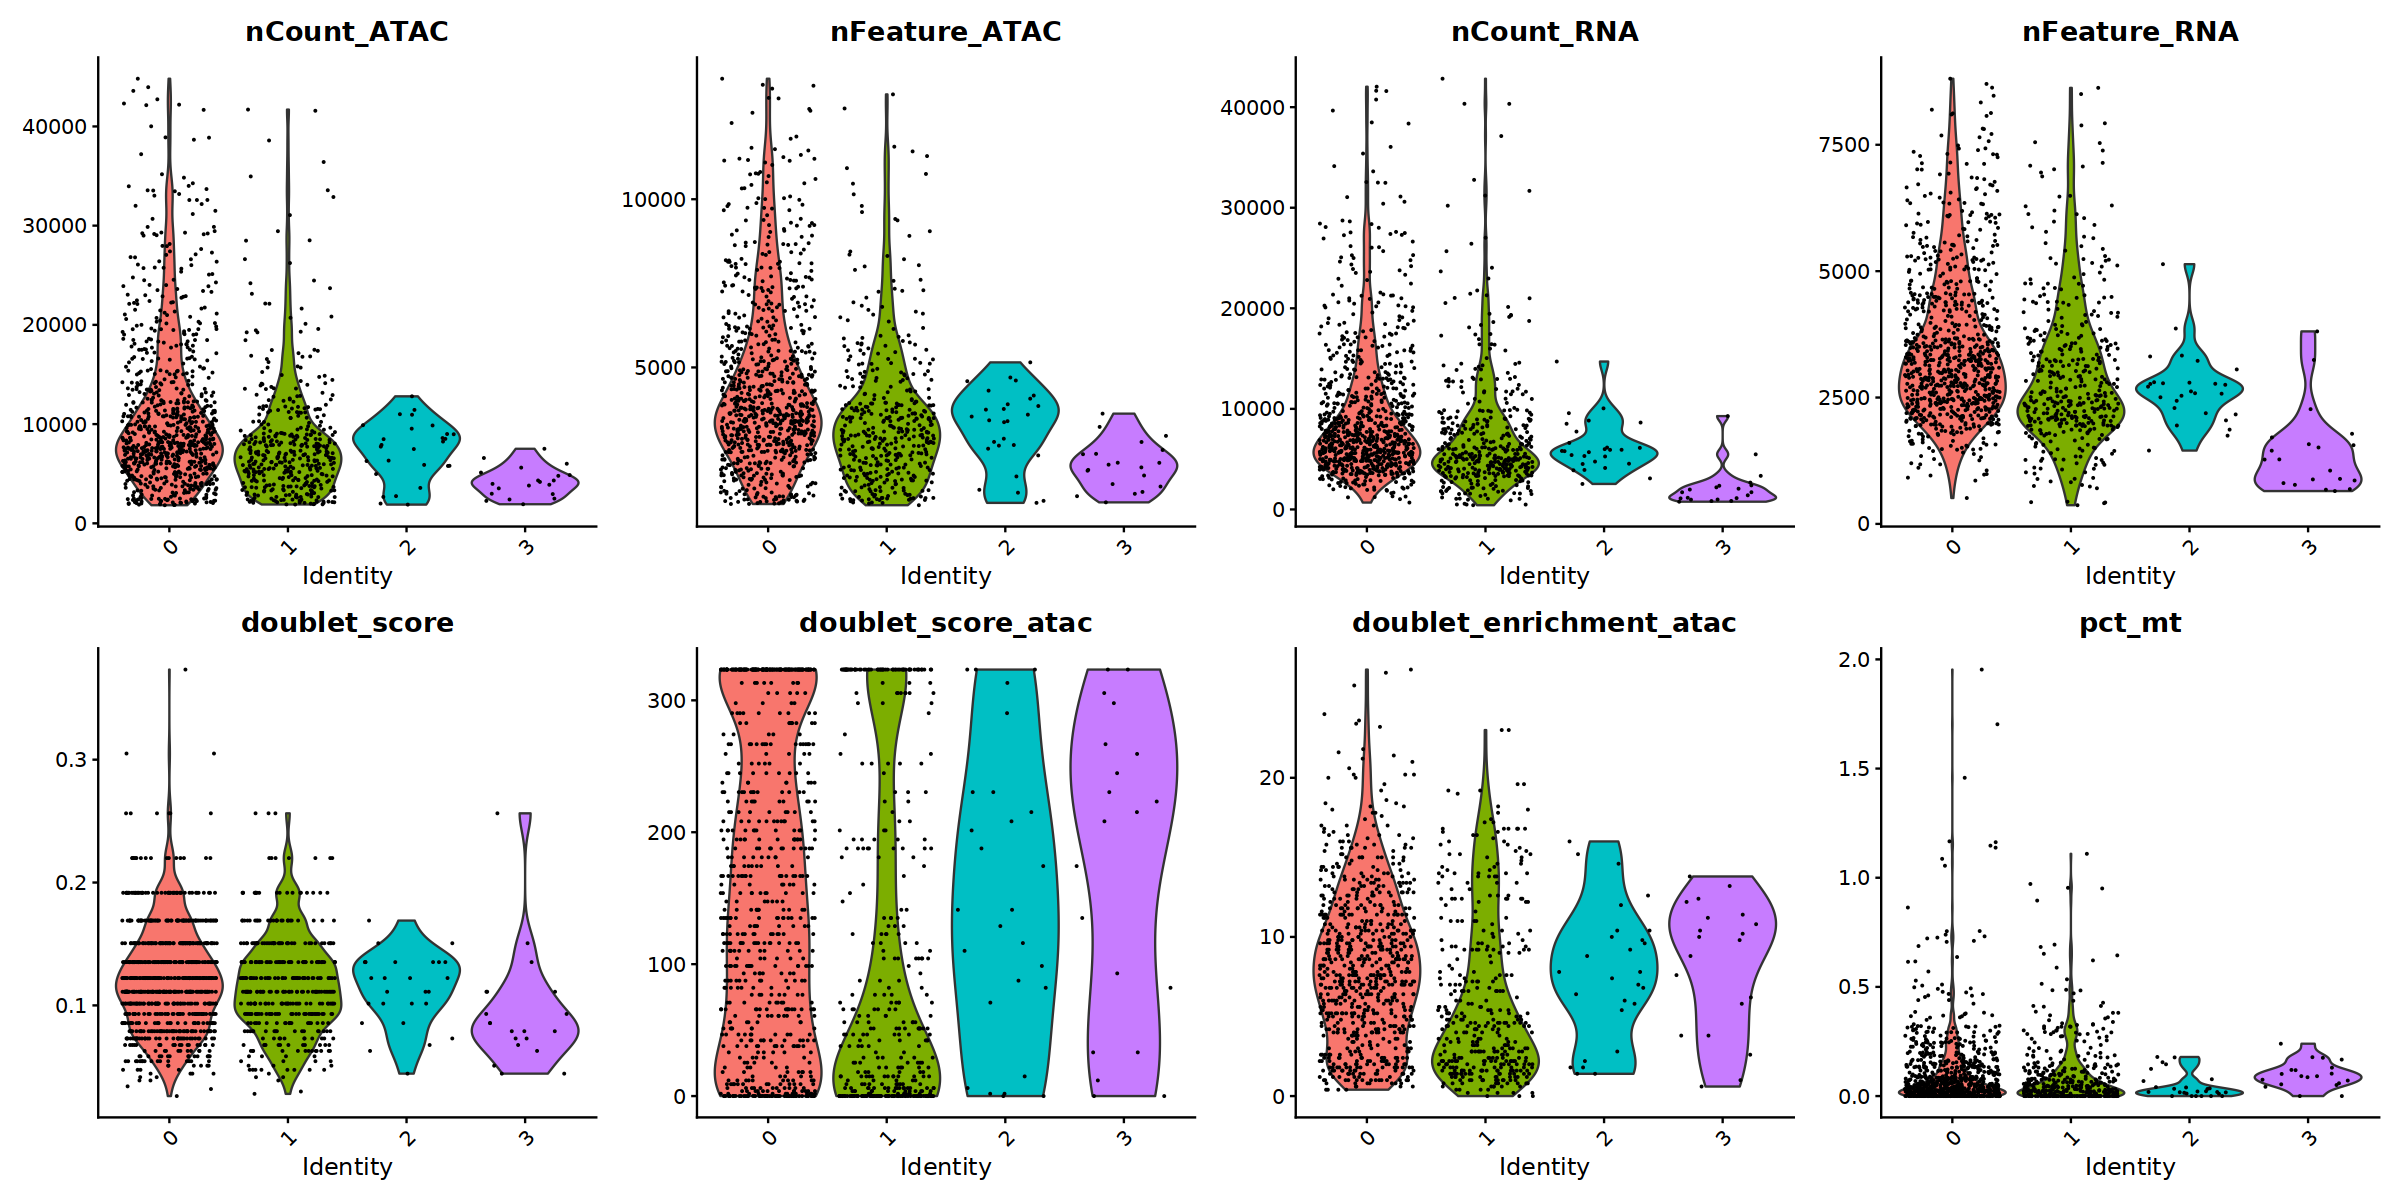

In [53]:
options(repr.plot.width = 20, repr.plot.height = 10)
VlnPlot(seurat_obj, feature=qc_vars, ncol = 4)

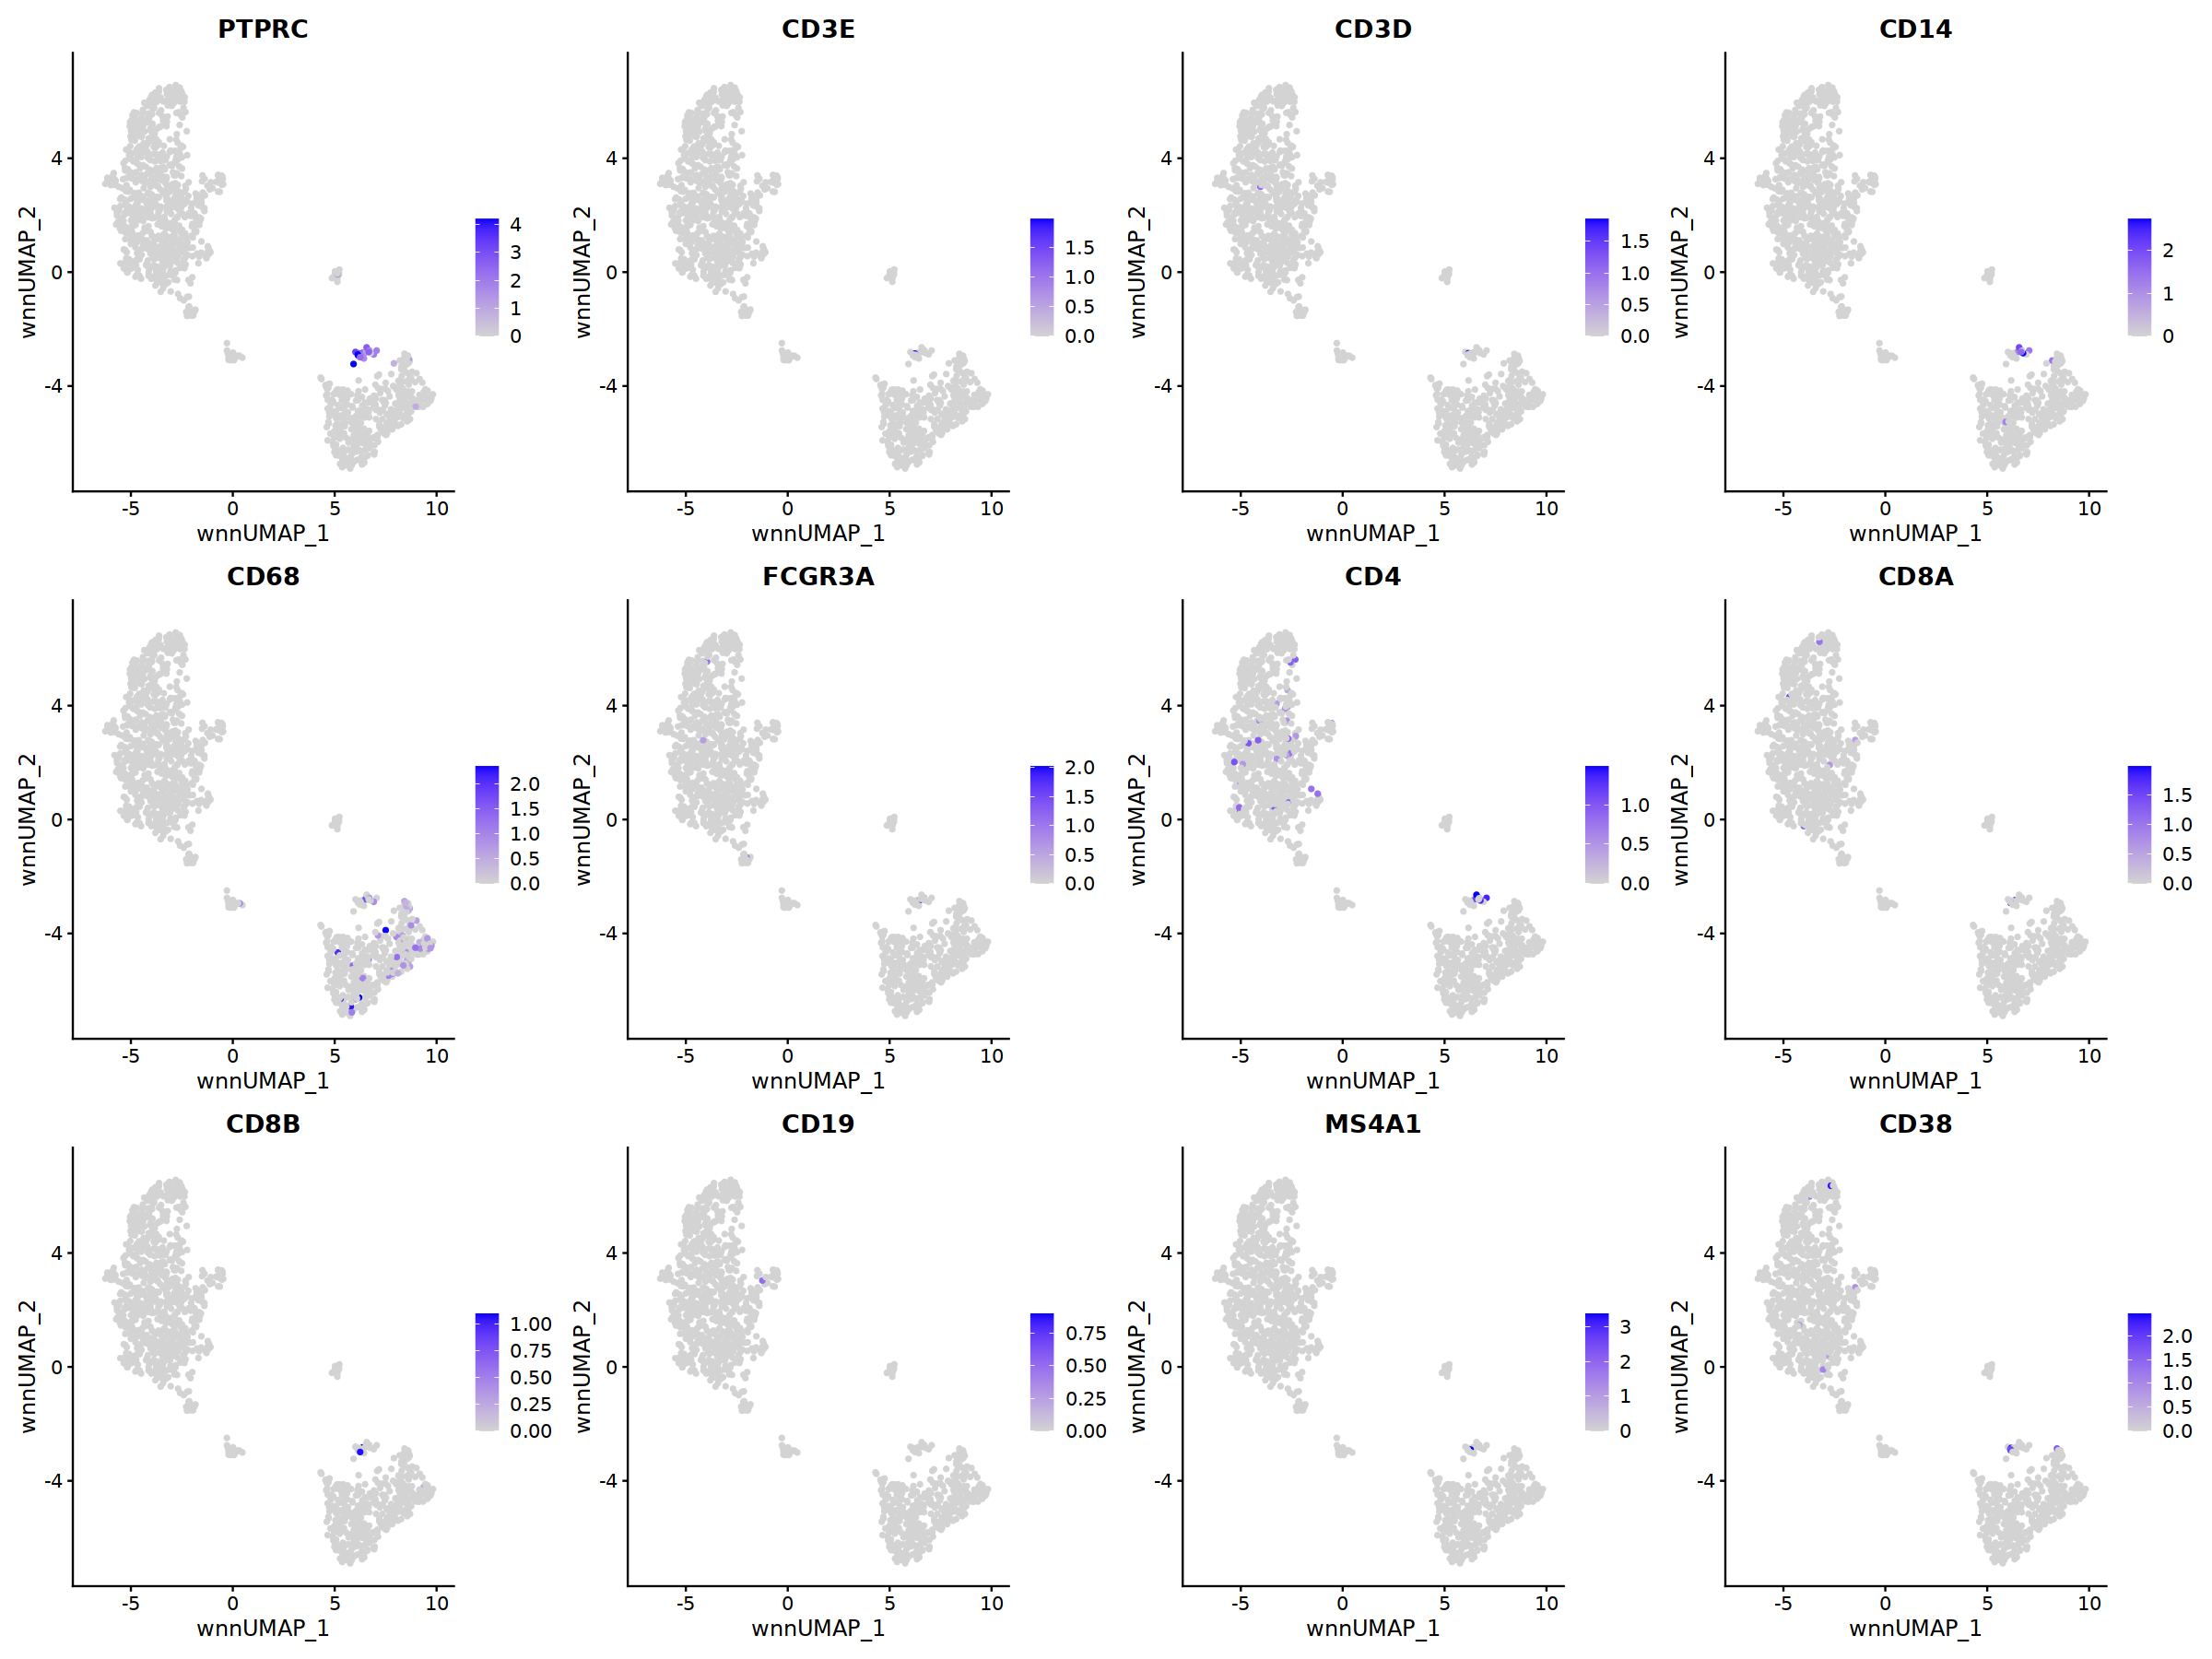

In [54]:
options(repr.plot.width = 20, repr.plot.height = 15)
immune <- c("PTPRC","CD3E", "CD3D", "CD14", "CD68", "FCGR3A", "CD4", "CD8A", "CD8B", "CD19", 
            "MS4A1", "CD38")

vars2plot <- exp_genes_plot(immune, seurat_obj)

FeaturePlot(seurat_obj, feature=vars2plot,reduction = "wnn.umap", ncol = 4)

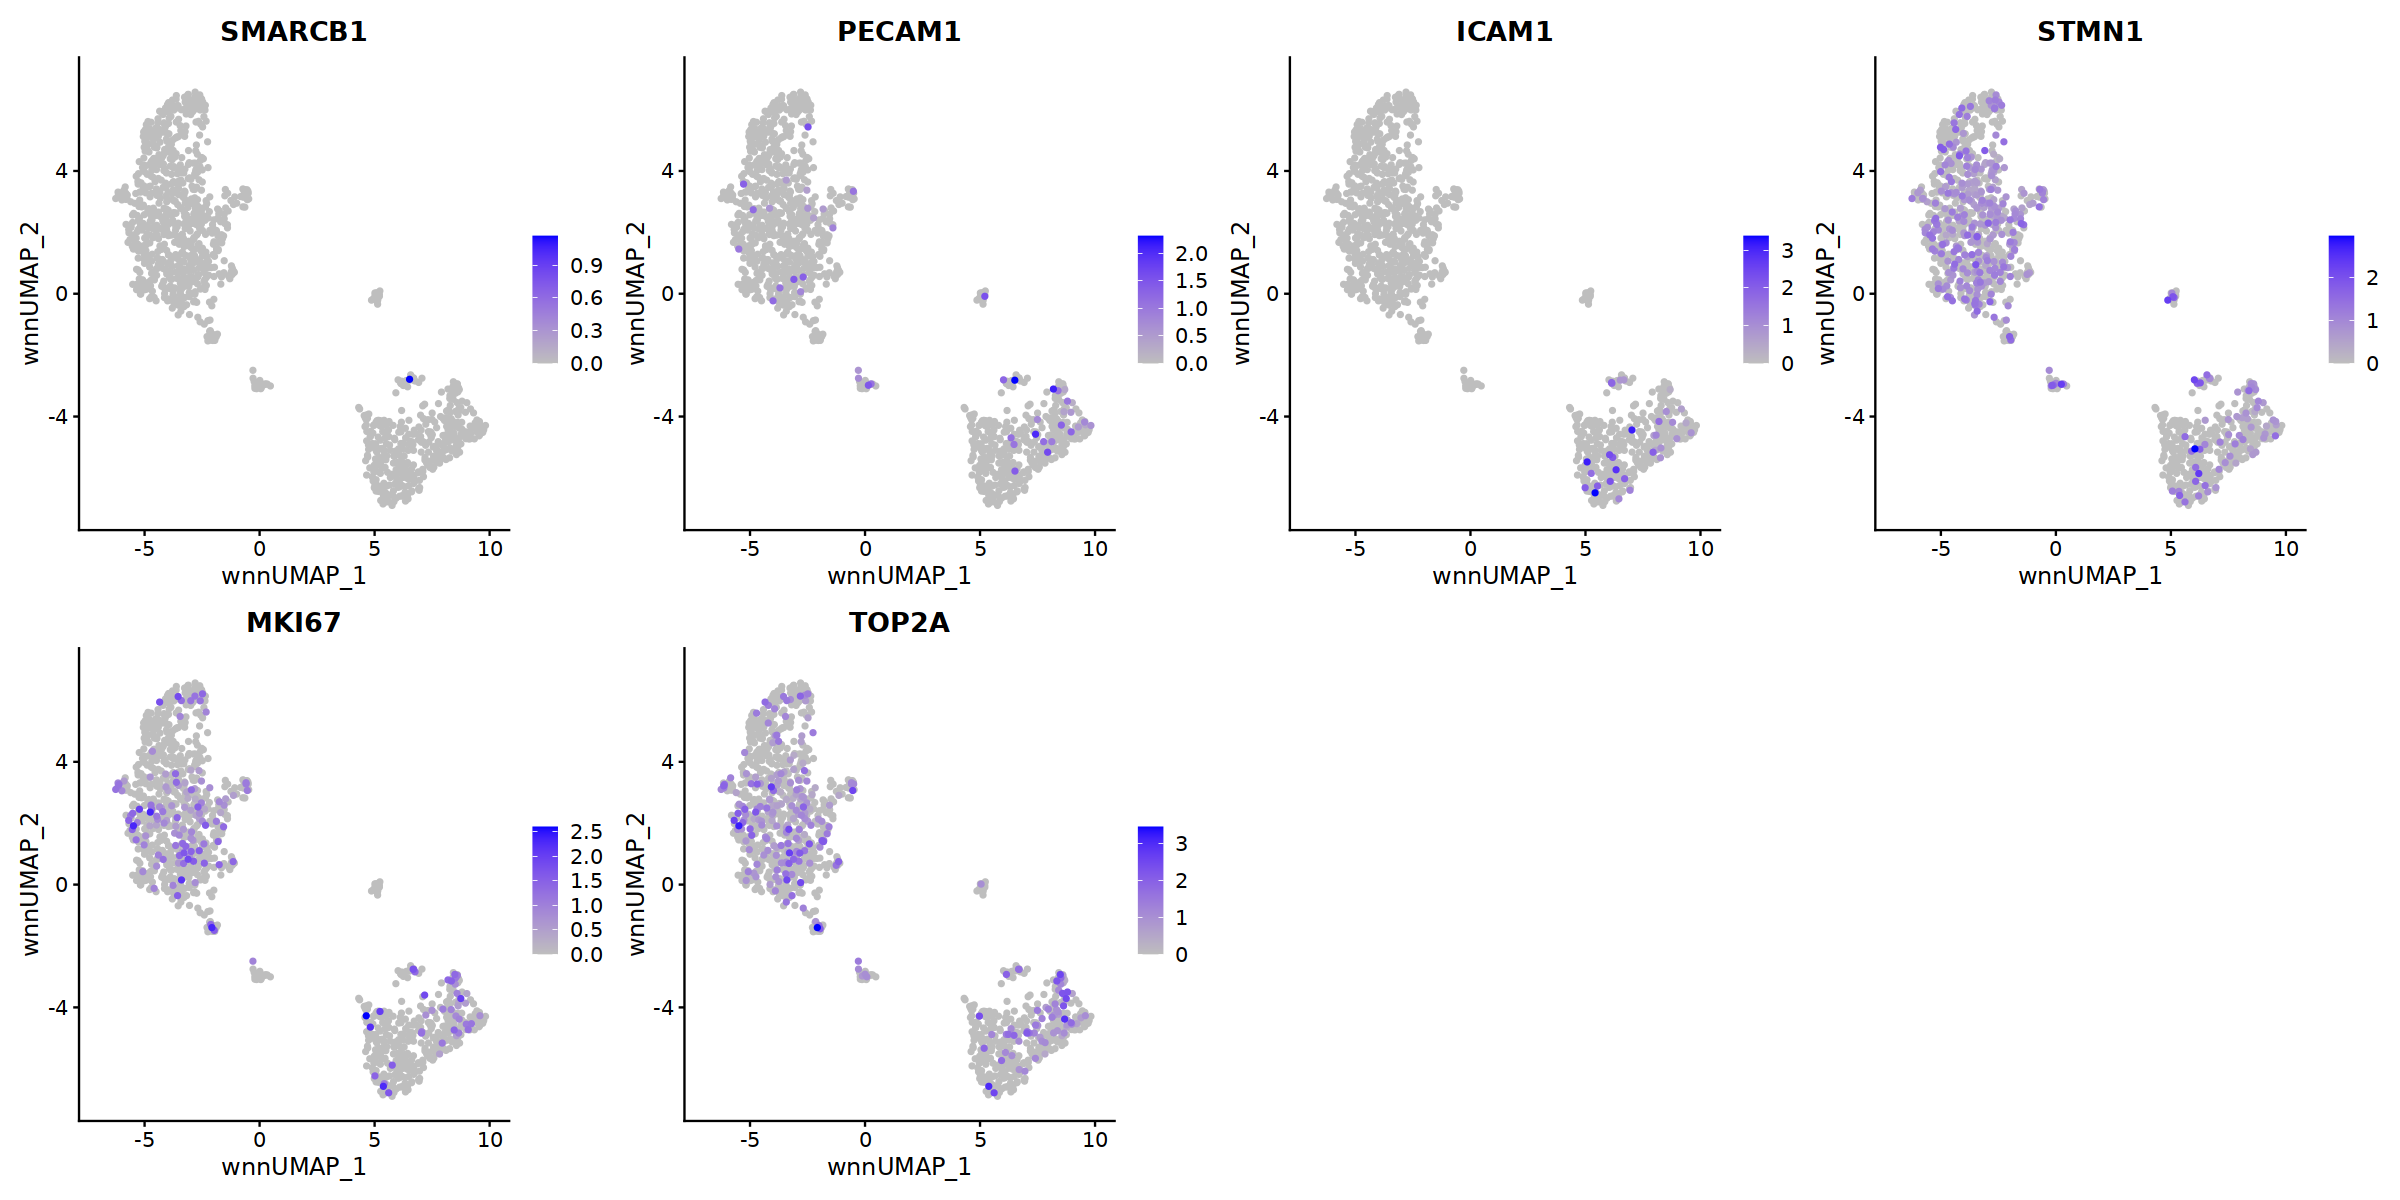

In [55]:
options(repr.plot.width = 20, repr.plot.height = 10)
other <- c("SMARCB1", "PECAM1","ICAM1","STMN1",
           "MKI67","TOP2A")

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=other, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

In [56]:
seurat_obj <- FindSubCluster(
  seurat_obj,
  cluster=1,
  graph.name = "wsnn",
  subcluster.name = "subclustering",
  resolution = 0.1,
  algorithm = 1
)

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 413
Number of edges: 15892

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9004
Number of communities: 2
Elapsed time: 0 seconds


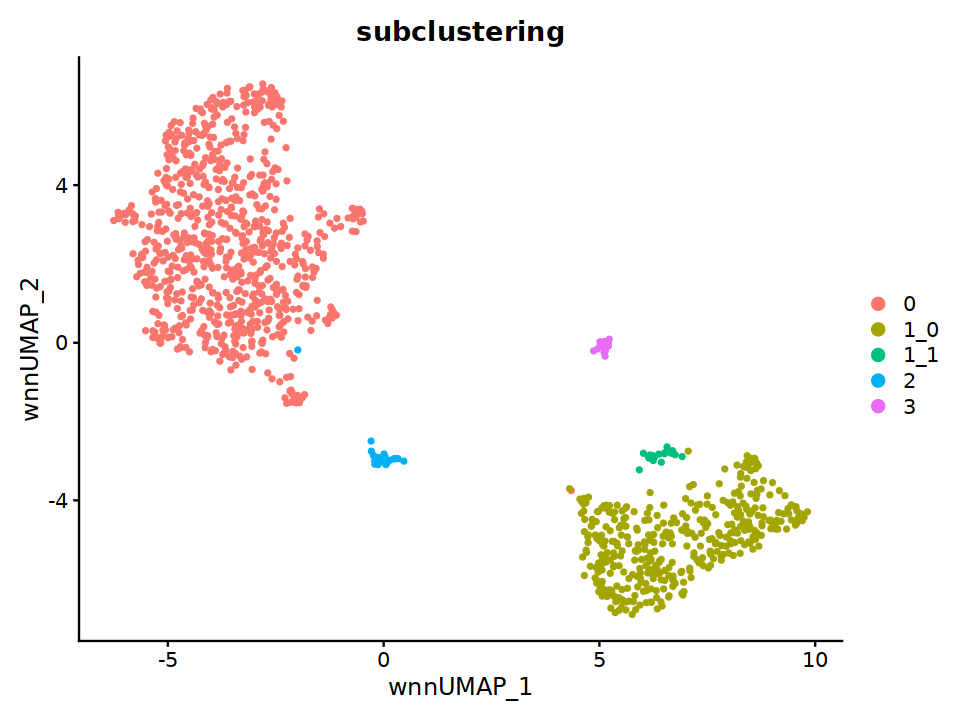

In [57]:
options(repr.plot.width = 8, repr.plot.height = 6)
DimPlot(seurat_obj, reduction = "wnn.umap", group.by = "subclustering")

In [58]:
seurat_obj <- SetIdent(seurat_obj, value=seurat_obj@meta.data$subclustering)

In [59]:
rna.markers <- FindAllMarkers(seurat_obj,only.pos = TRUE, min.pct = 0.1, 
                              logfc.threshold = 0.2)

Calculating cluster 1_0

Calculating cluster 3

Calculating cluster 0

Calculating cluster 2

Calculating cluster 1_1



In [60]:
rna.markers %>% 
  dplyr::filter(cluster == "0") %>%
  dplyr::filter(p_val_adj<0.05) %>% 
  arrange(desc(avg_log2FC)) %>% head(n=30)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
KCNMB2,2.896155e-105,3.577069,0.675,0.015,8.578121e-101,0,KCNMB2
IL1RAPL1,2.067634e-42,3.241171,0.388,0.035,6.124126e-38,0,IL1RAPL1
RALYL,1.469782e-57,3.124196,0.444,0.015,4.353346e-53,0,RALYL
DOK6,1.096871e-141,3.022778,0.892,0.111,3.248823e-137,0,DOK6
LRRTM4,1.249215e-24,2.974063,0.233,0.017,3.700050e-20,0,LRRTM4
TMEFF2,9.142911e-80,2.940753,0.604,0.048,2.708039e-75,0,TMEFF2
COL11A1,9.015446e-42,2.883681,0.589,0.243,2.670285e-37,0,COL11A1
CNTNAP2,2.050220e-22,2.862439,0.256,0.041,6.072547e-18,0,CNTNAP2
ADGRL3,1.145709e-52,2.825295,0.552,0.154,3.393477e-48,0,ADGRL3


### Rename

In [61]:
rename_clusters <- c("0"="Tumor TMEFF2", "1_0"="Tumor ANXA2",
                     "1_1"="Immune Cells", "2"="Tumor TAFA2",
                     "3"="Stromal")

seurat_obj <- RenameIdents(object = seurat_obj, rename_clusters)
seurat_obj$clusters <- Idents(seurat_obj)

In [62]:
cols_keep <- c('nCount_ATAC', 'nFeature_ATAC', 'nCount_RNA', 'nFeature_RNA', 
               'is_cell', 'atac_fragments', 'atac_peak_region_fragments', 
               'fragments', 'mononucleosomal', 'nucleosome_free', 'reads_count', 
               'FRiP', 'caller', 'nucleosome_signal', 'nucleosome_percentile', 
               'TSS.enrichment', 'TSS.percentile', 'high.tss', 'pct_mt', 
               'pct_ribosomal', 'doublet_score', 'doublet_pred', 'doublet_score_atac',
               'doublet_enrichment_atac', 'S.Score', 'G2M.Score', 'Phase',
               'RNA.weight', 'ATAC.weight', 'nCount_RNA_decontx','nFeature_RNA_decontx', 
               'RNA_decontx.weight','seurat_clusters','clusters')

seurat_obj@meta.data <- seurat_obj@meta.data[,cols_keep] 

In [63]:
rna.markers <- rna.markers %>% 
      mutate(cluster = as.character(cluster)) %>% 
      mutate(annotation = rename_clusters[cluster])

In [64]:
readr::write_csv(rna.markers, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l2_anno_{patient}.csv")))

In [65]:
df_meta <- seurat_obj@meta.data

df_meta <- df_meta %>% 
      mutate(cell_groups = case_when(
      str_detect(clusters, "Tumor") ~ "Tumor",
      clusters == "Immune Cells" | clusters == "T-cells" | clusters == 'Plasma B-cell' ~ "Immune",
      str_detect(clusters, "Macrophage") ~ "Immune",
      TRUE ~ "Other stromal"))

seurat_obj@meta.data$cell_groups <- df_meta$cell_groups

In [66]:
seurat_obj <- SetIdent(seurat_obj, value=seurat_obj@meta.data$cell_groups)
rna.markers <- FindAllMarkers(seurat_obj,only.pos = TRUE, min.pct = 0.1, logfc.threshold = 0.2)
readr::write_csv(rna.markers, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l1_anno_{patient}.csv")))

Calculating cluster Tumor

Calculating cluster Other stromal

Calculating cluster Immune



In [67]:
color_labels <- generate_color(unique(Idents(seurat_obj)))

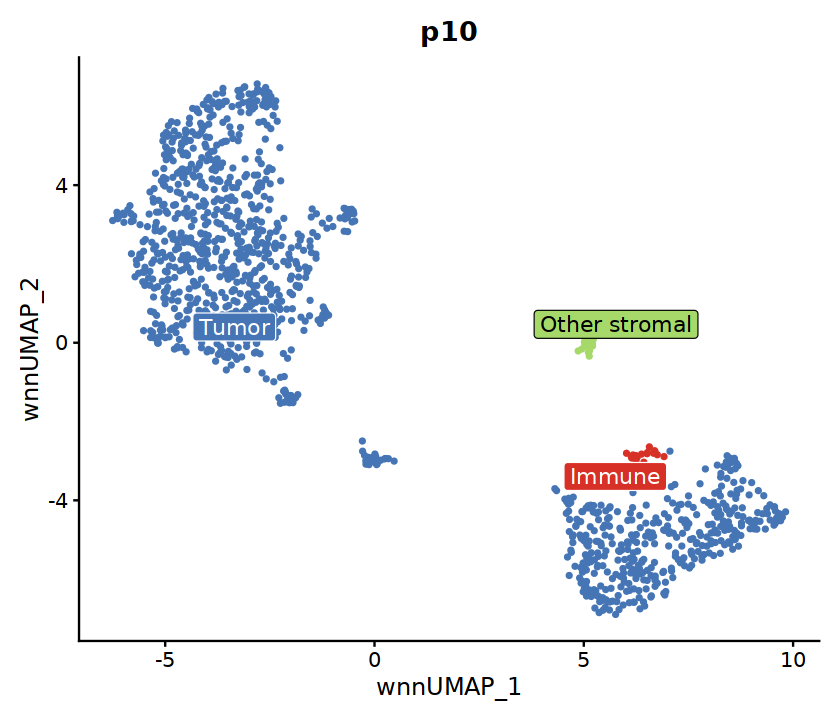

In [68]:
options(repr.plot.width = 7, repr.plot.height = 6)
l1 <- DimPlot(seurat_obj, 
        reduction = "wnn.umap", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = c("Immune"="#d73027", "Other stromal"="#a6d96a","Tumor"="#4575b4")) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
l1

In [69]:
ggsave(plot = l1, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP_l1.svg")))

In [70]:
seurat_obj <- SetIdent(seurat_obj, value=seurat_obj@meta.data$clusters)

In [71]:
color_labels <- generate_color(unique(Idents(seurat_obj)))

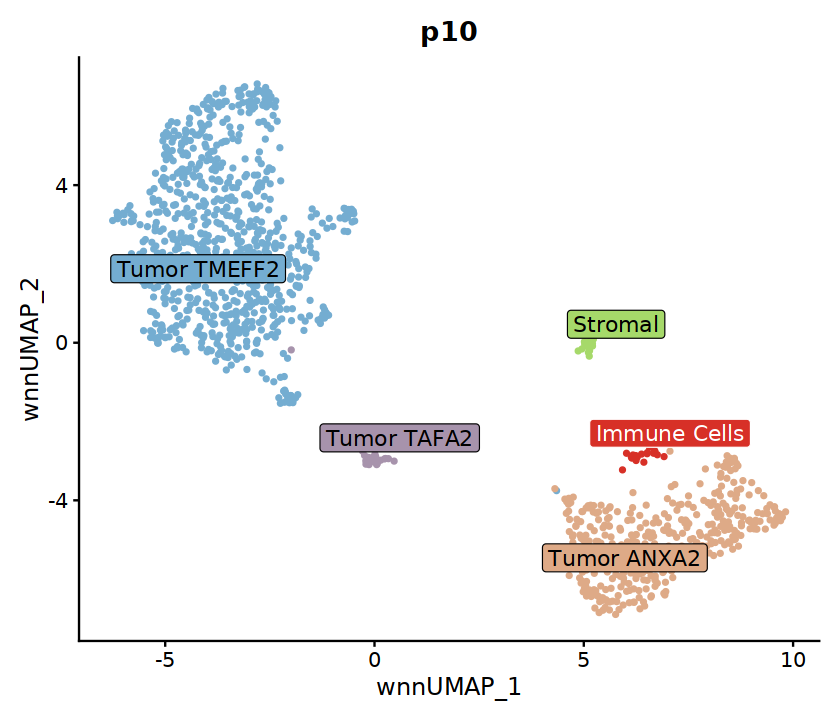

In [72]:
options(repr.plot.width = 7, repr.plot.height = 6)
p_clust <- DimPlot(seurat_obj, 
        reduction = "wnn.umap", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))

p_clust

In [73]:
ggsave(plot = p_clust, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP.svg")))
ggsave(plot = p_clust, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP_l2.png")))

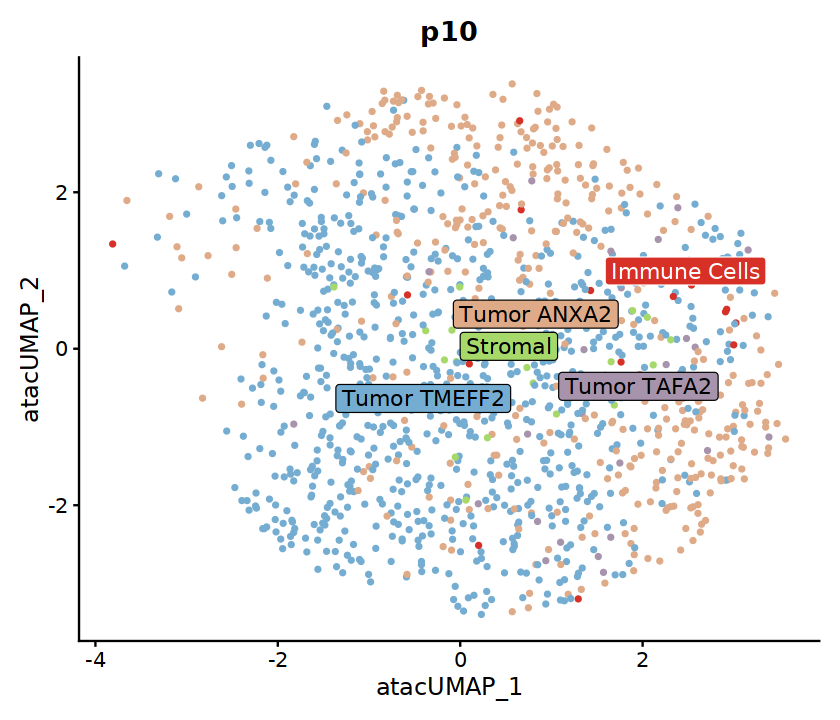

In [74]:
options(repr.plot.width = 7, repr.plot.height = 6)
DimPlot(seurat_obj, 
        reduction = "umap.atac", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))


In [75]:
# Calculate the variance explained 
stdev <- Stdev(seurat_obj, reduction = "pca")

var_explained <- (stdev^2) / sum(stdev^2) * 100

pc1_label <- paste0("PC1: ", round(var_explained[1], 2), "% var.")
pc2_label <- paste0("PC2: ", round(var_explained[2], 2), "% var.")

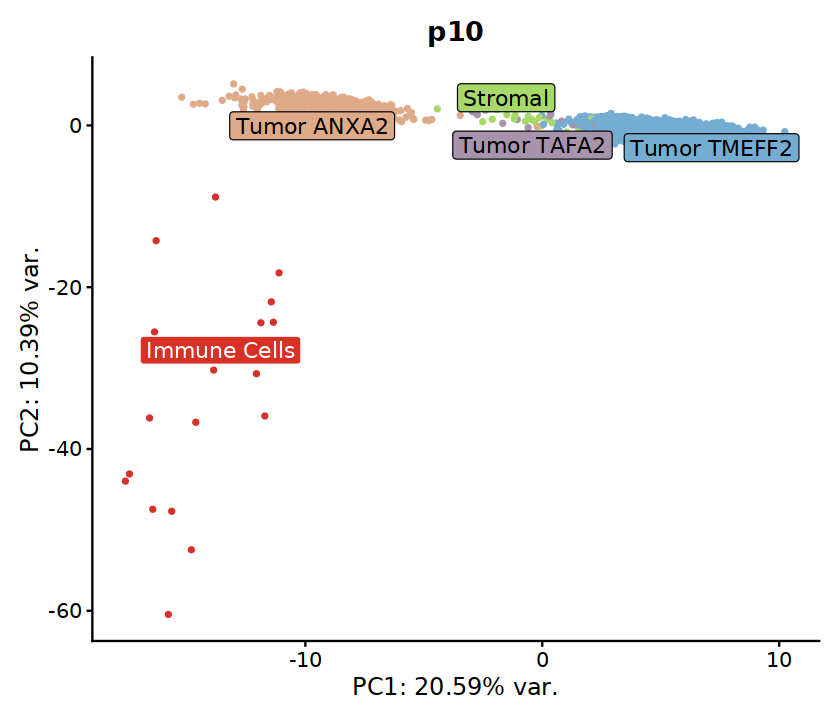

In [76]:
p_pca <- DimPlot(seurat_obj, 
        reduction = "pca", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    xlab(pc1_label) +
    ylab(pc2_label) +
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
p_pca 

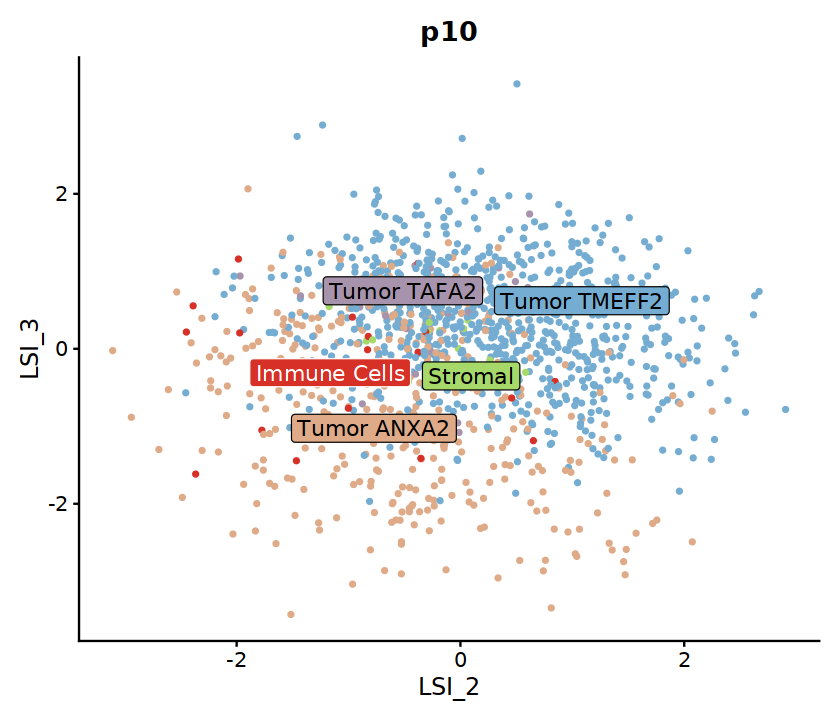

In [77]:
p_lsi <- DimPlot(seurat_obj, 
        reduction = "lsi.atac", 
        dims = c(2, 3),
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        repel = TRUE,
        label.color = as.list(color_labels),
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
p_lsi

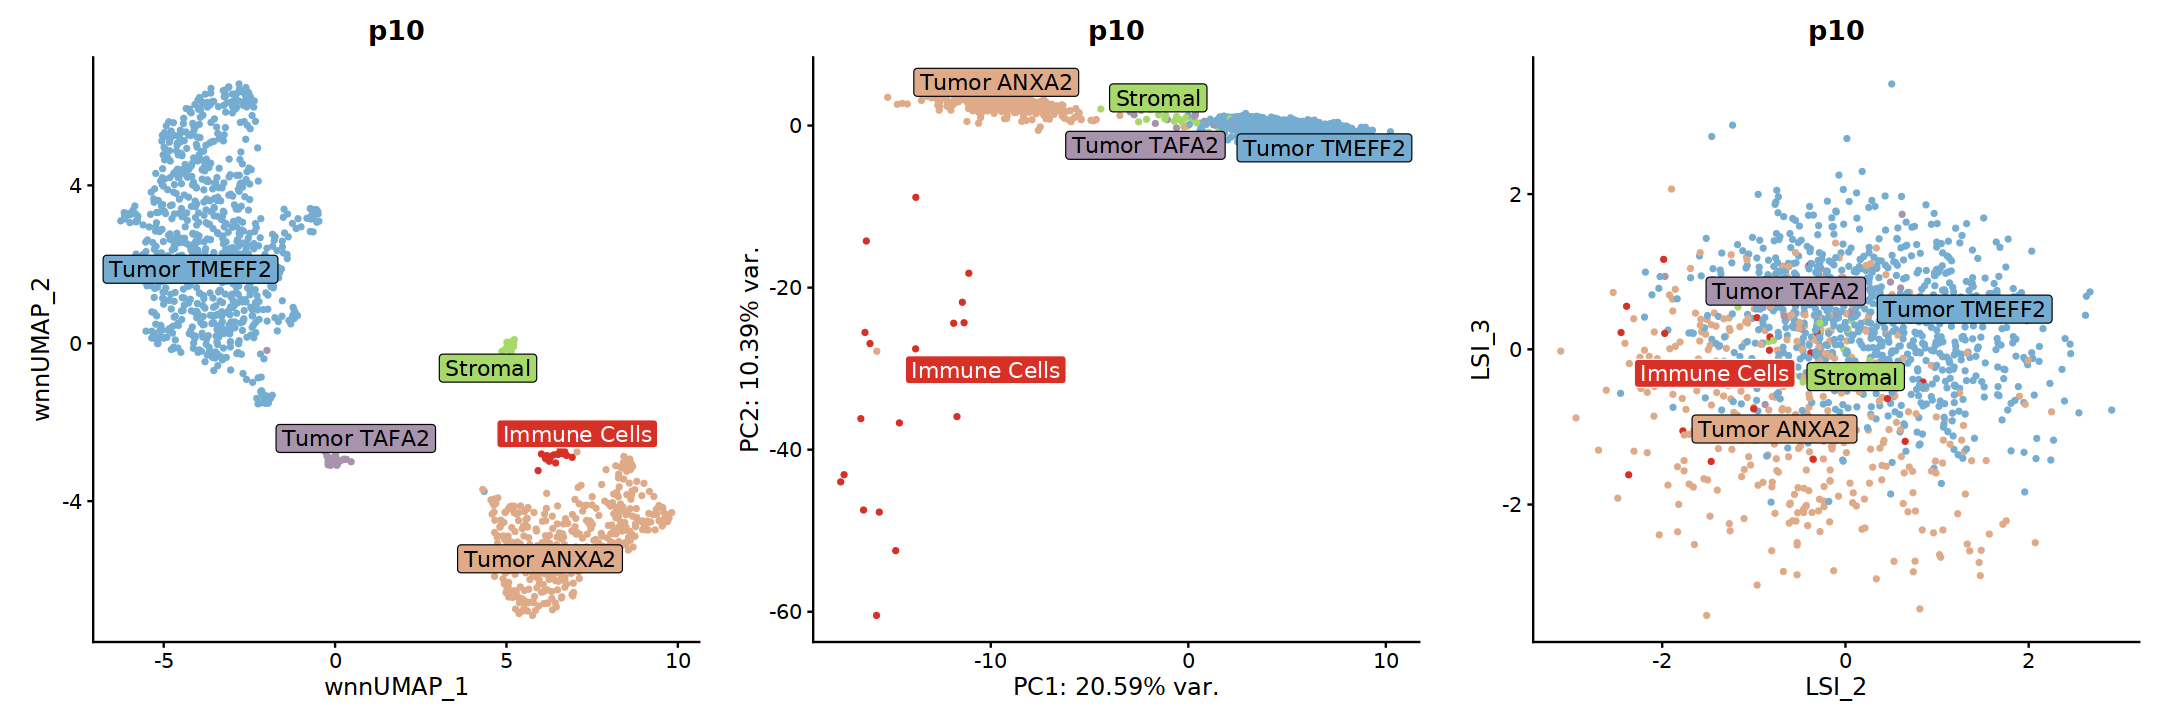

In [78]:
options(repr.plot.width = 18, repr.plot.height = 6)
cp <- cowplot::plot_grid(p_clust, p_pca, p_lsi,
                   align = "hv",
                   axis = "trbl",
                   ncol = 3,
                   nrow = 1)
cp

In [79]:
ggsave(plot = cp, width = 18, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_reductions.png")))

Pseudo-bulk per cluster

In [80]:
var_name <- paste0("markers_", patient)
markers_clust <- get(var_name)

markers <- unlist(markers_clust, use.names = F)
markers <- c(c("MEOX2", "BMP4", "GPC6"), markers) ## common markers to all clusters

In [81]:
Idents(seurat_obj) <- factor(Idents(seurat_obj), levels = names(markers_clust))

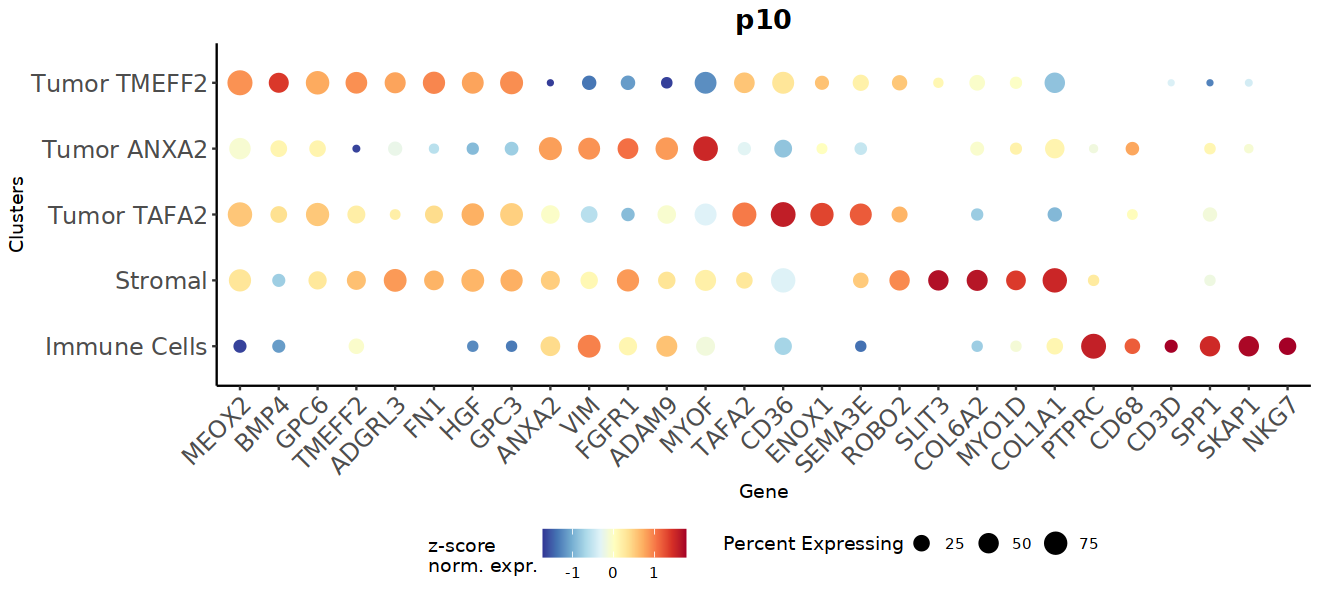

In [82]:
options(repr.plot.width = 11, repr.plot.height = 5, warn=-1,verbose = FALSE)
dp1 <- custom_dp(seurat_obj, markers, TRUE,patient)
dp1

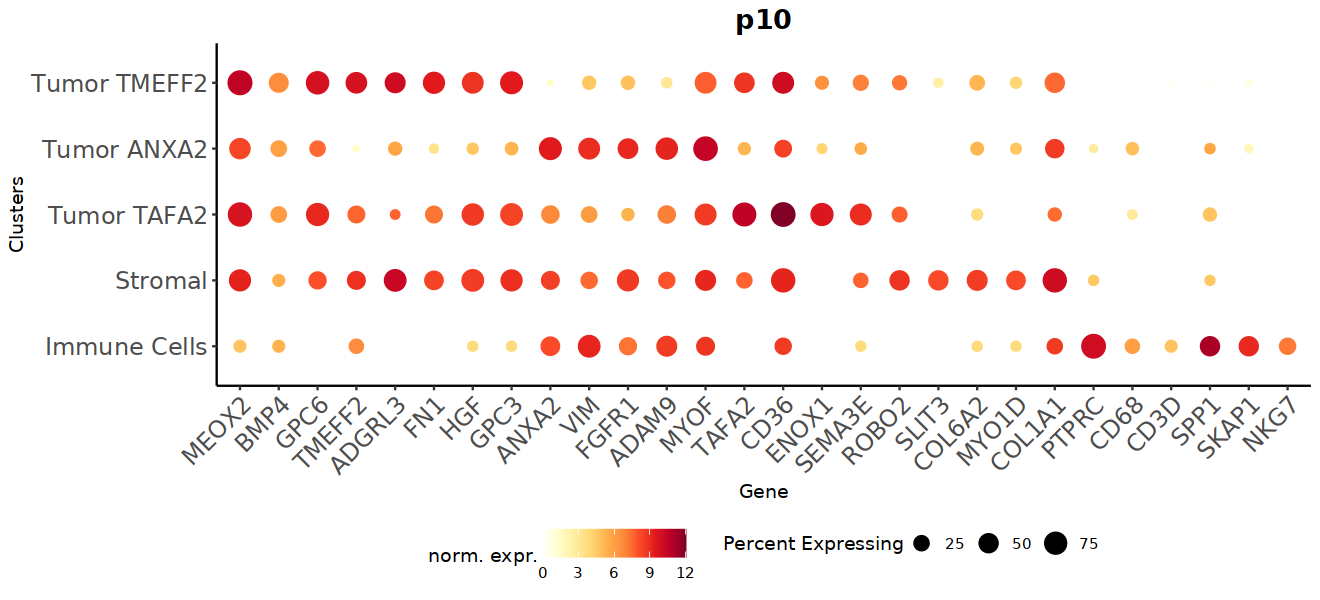

In [83]:
options(repr.plot.width = 11, repr.plot.height = 5, warn=-1,verbose = FALSE)
dp2 <- custom_dp(seurat_obj, markers, FALSE,patient)
dp2

In [84]:
ggsave(plot = dp1, width = 10, height = 5, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_dotplot.svg")))
ggsave(plot = dp1, width = 10, height = 5, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_dotplot.png")))

## Save

In [85]:
# keep original metrics
seurat_obj$ncount_rna <- seurat_obj$nCount_RNA
seurat_obj$nfeature_rna <- seurat_obj$nFeature_RNA

In [86]:
seurat_obj$RNA <- NULL
seurat_obj[['RNA']] = seurat_obj[[assay_ch]]
DefaultAssay(seurat_obj) <- "RNA"
seurat_obj$RNA_decontx <- NULL

In [87]:
saveRDS(seurat_obj, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l2_anno_{patient}.rds")))

## Session

In [88]:
sessionInfo()

R version 4.1.1 (2021-08-10)
Platform: x86_64-conda-linux-gnu (64-bit)
Running under: CentOS Linux 7 (Core)

Matrix products: default
BLAS/LAPACK: /home/groups/singlecell/isentis/conda_envs/ines_r4.1.1c/lib/libopenblasp-r0.3.24.so

locale:
 [1] LC_CTYPE=es_ES.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=es_ES.UTF-8        LC_COLLATE=es_ES.UTF-8    
 [5] LC_MONETARY=es_ES.UTF-8    LC_MESSAGES=es_ES.UTF-8   
 [7] LC_PAPER=es_ES.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=es_ES.UTF-8 LC_IDENTIFICATION=C       

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] scater_1.22.0               scran_1.22.1               
 [3] scuttle_1.4.0               SingleCellExperiment_1.16.0
 [5] SummarizedExperiment_1.24.0 Biobase_2.54.0             
 [7] GenomicRanges_1.46.1        GenomeInfoDb_1.30.1        
 [9] IRanges_2.28.0    